In [1]:
# !pip install gensim

# Dataset Load

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re
import seaborn as sns
from collections import Counter
from nltk.stem import WordNetLemmatizer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

In [20]:
# nltk.download('punkt')
# nltk.download('stopwords')
# nltk.download('punkt_tab')

In [21]:
path = "/kaggle/input/qa-test-train/Training_Question Answer Classification Dataset 5.csv"
qa = pd.read_csv(path)
qa.head(10)

,QA Text,Class
0,Question Title:\ni am good at web design amate...,Business & Finance
1,Question Title:\nMy daughter wants to be a Med...,Education & Reference
2,Question Title:\nIs brother Jesus our brother ...,Society & Culture
3,Question Title:\nwhat is I-20?\nQuestion Conte...,Education & Reference
4,Question Title:\nwhat is a data disk?\nQuestio...,Computers & Internet
5,Question Title:\nDon't you think that all thos...,Entertainment & Music
6,Question Title:\nwhy do people have all the se...,Society & Culture
7,Question Title:\nWho is the oldest golfer to h...,Sports
8,Question Title:\nwhat is a loan guarantor? (on...,Business & Finance
9,Question Title:\nwhat is the meaning of Magi c...,Education & Reference


In [22]:
path2 = "/kaggle/input/qa-test-train/Test_Question Answer Classification Dataset.csv"
test = pd.read_csv(path2)

In [23]:
qa.dtypes

QA Text    object
Class      object
dtype: object

# EDA

In [7]:
print("Shape of dataset:", qa.shape)
print("\nColumns:", qa.columns.tolist())
print("\nData Types:\n", qa.dtypes)
print("\nMissing Values:\n", qa.isnull().sum())
print("\nFirst 5 rows:\n", qa.head())

Shape of dataset: (280003, 2)

Columns: ['QA Text', 'Class']

Data Types:
 QA Text    object
Class      object
dtype: object

Missing Values:
 QA Text    0
Class      0
dtype: int64

First 5 rows:
                                              QA Text                  Class
0  Question Title:\ni am good at web design amate...     Business & Finance
1  Question Title:\nMy daughter wants to be a Med...  Education & Reference
2  Question Title:\nIs brother Jesus our brother ...      Society & Culture
3  Question Title:\nwhat is I-20?\nQuestion Conte...  Education & Reference
4  Question Title:\nwhat is a data disk?\nQuestio...   Computers & Internet


In [8]:
qa['Class'].value_counts()

Class
Entertainment & Music     28267
Health                    28186
Sports                    28074
Science & Mathematics     28039
Computers & Internet      27980
Education & Reference     27972
Business & Finance        27953
Family & Relationships    27905
Society & Culture         27881
Politics & Government     27746
Name: count, dtype: int64

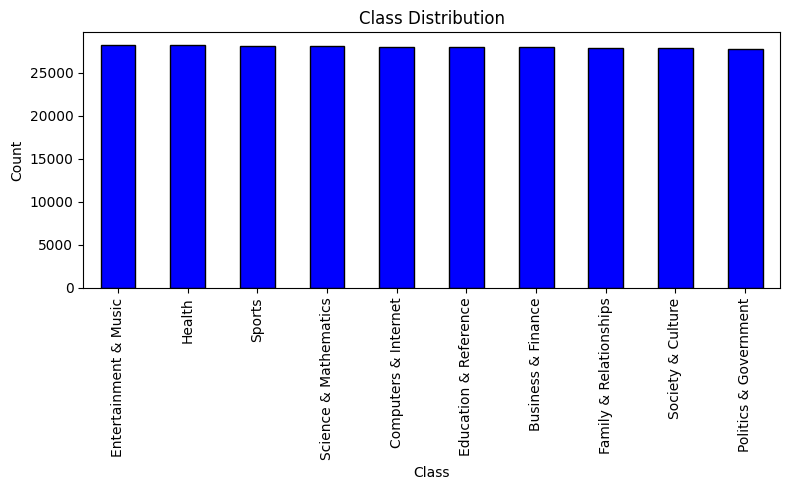

In [9]:
class_counts = qa['Class'].value_counts()

plt.figure(figsize=(8, 5))
class_counts.plot(kind='bar', color='blue', edgecolor='black')

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

From the above class distribution bar plot, we can see that the class is distributed uniformly. So, we don't need to do upsampling or downsampling

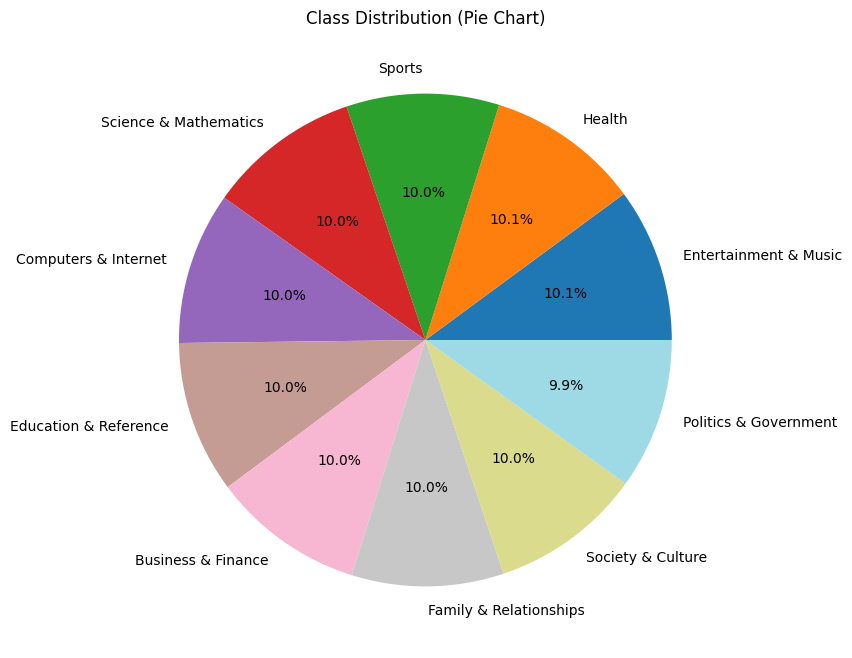

In [10]:
qa['Class'].value_counts().plot.pie(autopct='%1.1f%%', figsize=(8,8), colormap="tab20")
plt.title("Class Distribution (Pie Chart)")
plt.ylabel("")
plt.show()

From the pie chart, it can be seen that all the classes are distributed uniformly, as the percentage of the classes are almost similar to each other.

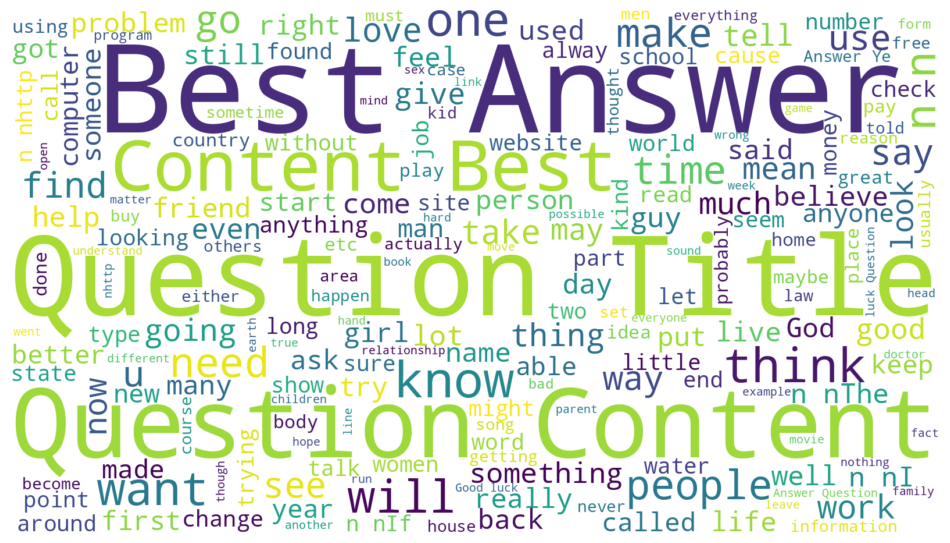

In [24]:
text = " ".join(qa["QA Text"].astype(str))

wordcloud = WordCloud(width=1600, height=900, background_color='white').generate(text)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()


From the word cloud, it can be seen that **Question, Content, Best, Answer, and Title** are in high number. This means these words comes multiple times in the whole dataset.

In [ ]:
all_text = ' '.join(qa['QA Text'].tolist())
tokens = word_tokenize(all_text)

fdist = FreqDist(tokens)

most_common = fdist.most_common(20)
words = [word for word, freq in most_common]
frequencies = [freq for word, freq in most_common]

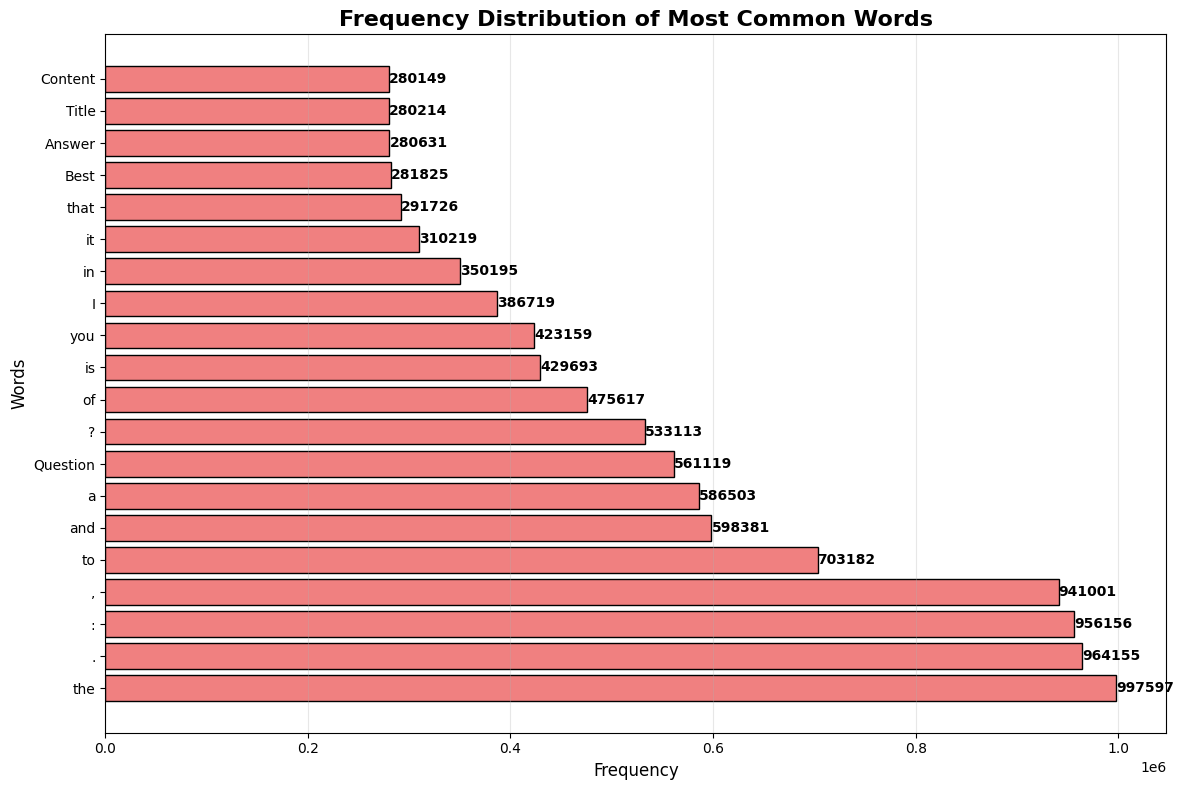

In [14]:
plt.figure(figsize=(12, 8))
bars = plt.barh(words, frequencies, color='lightcoral', edgecolor='black')

for i, (bar, freq) in enumerate(zip(bars, frequencies)):
    plt.text(freq + 0.1, bar.get_y() + bar.get_height()/2, str(freq), ha='left', va='center', fontweight='bold')

plt.title('Frequency Distribution of Most Common Words', fontsize=16, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Words', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

From the above Bar chart, it can be said that most common words are **the, some punctuations and to**. Also there are some stopwords and redundant words present which are in large number. We have to remove it.

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


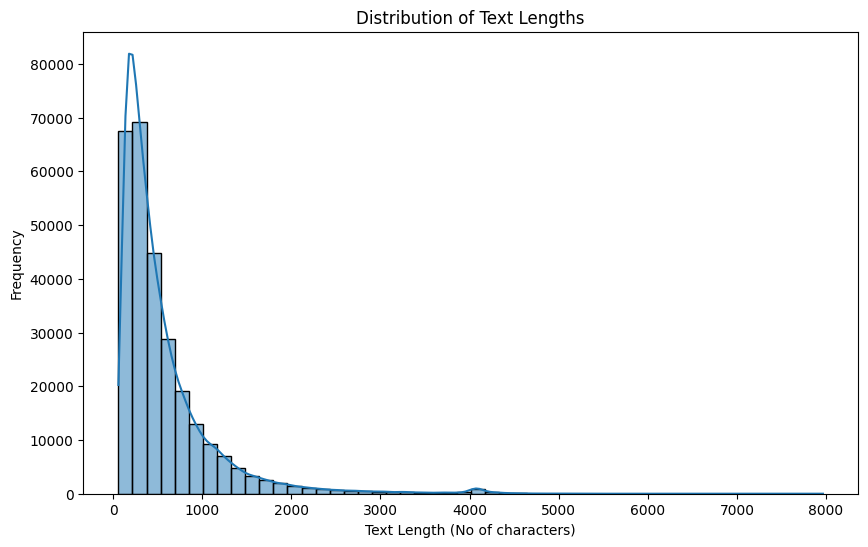

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


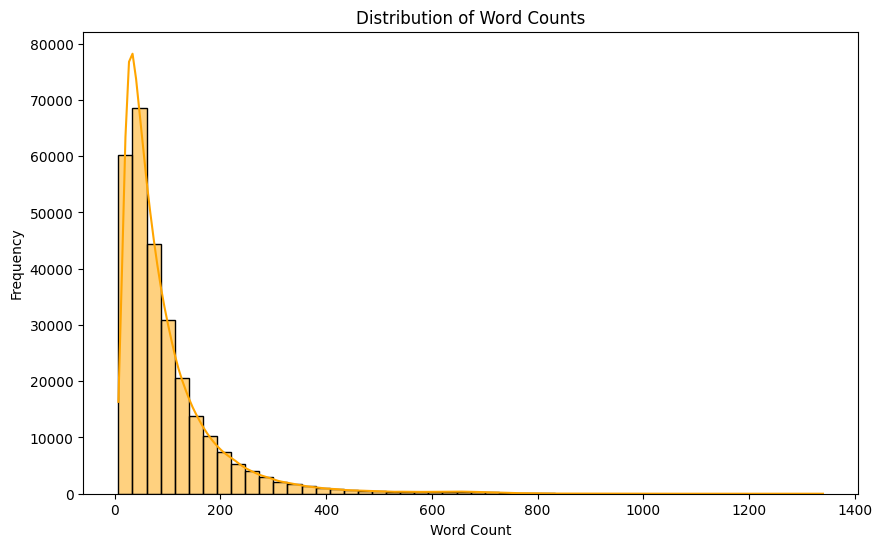

In [15]:
qa["text_length"] = qa["QA Text"].astype(str).apply(len)
qa["word_count"] = qa["QA Text"].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(10,6))
sns.histplot(qa["text_length"], bins=50, kde=True)
plt.title("Distribution of Text Lengths")
plt.xlabel("Text Length (No of characters)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10,6))
sns.histplot(qa["word_count"], bins=50, kde=True, color="orange")
plt.title("Distribution of Word Counts")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

From the above plot, it can be said that texts which are present in the dataset, are most of them has length of 1000 or less, and the word count for most of the texts has 200 or less.

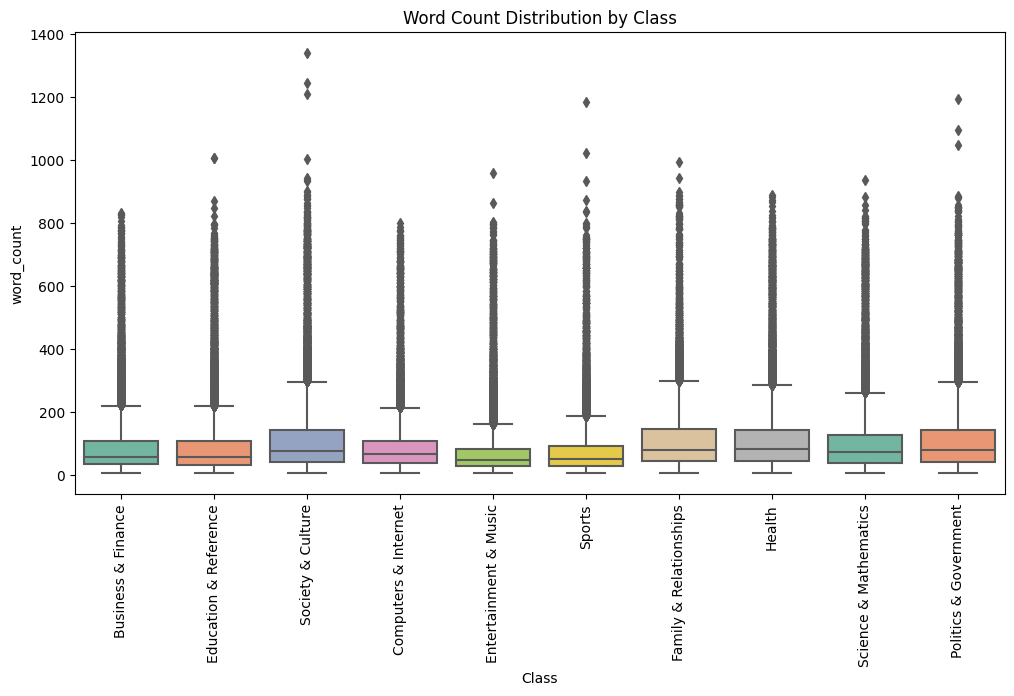

In [16]:
plt.figure(figsize=(12,6))
sns.boxplot(data=qa, x="Class", y="word_count", palette="Set2")
plt.xticks(rotation=90)
plt.title("Word Count Distribution by Class")
plt.show()

From the boxplot, it can be said that-

**Typical Length:** In most categories, the median word count for typical texts generally ranges from 50 to 250 words, with the mid-range typically falling between 100 and 200 words.

**Presence of Long Texts:** While the majority of texts are relatively concise, it is important to note that there are instances of longer texts that exist as outliers. These outliers, represented by smaller circles, can extend beyond 1,200 words, indicating that while most contributions are brief, each category may also feature some notably extensive articles.

In [17]:
stop_words = set(stopwords.words("english"))

def clean_text(text):
    tokens = [w.lower() for w in text.split() if w.isalpha()]
    tokens = [w for w in tokens if w not in stop_words]
    return tokens

all_words = []
qa["QA Text"].astype(str).apply(lambda x: all_words.extend(clean_text(x)))

word_freq = Counter(all_words).most_common(20)

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


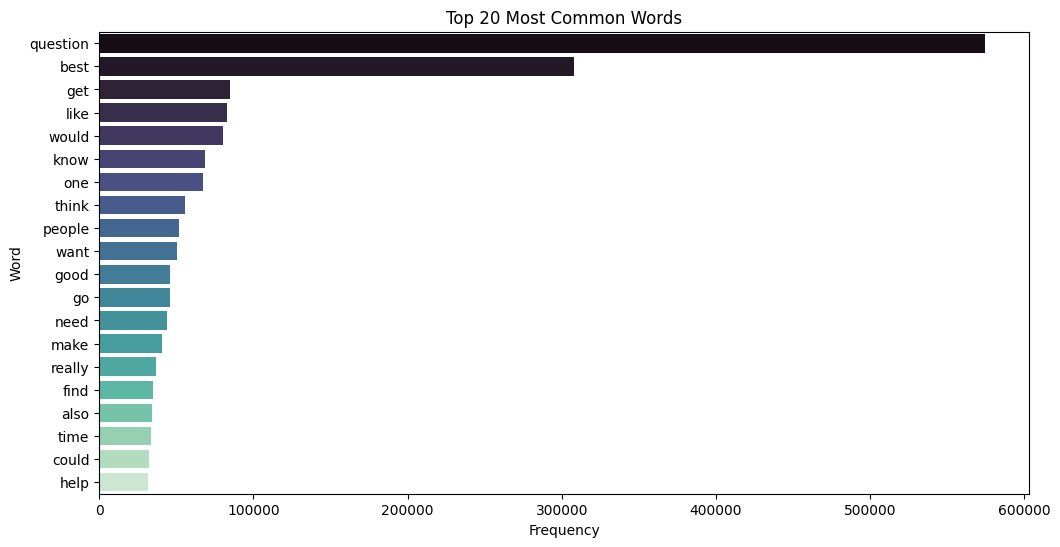

In [18]:
words, counts = zip(*word_freq)
plt.figure(figsize=(12,6))
sns.barplot(x=list(counts), y=list(words), palette="mako")
plt.title("Top 20 Most Common Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

After cleaning the punctuation and other unnecessary words like stopwords, the barplot shows that there present a word **question and best** in large numbers.

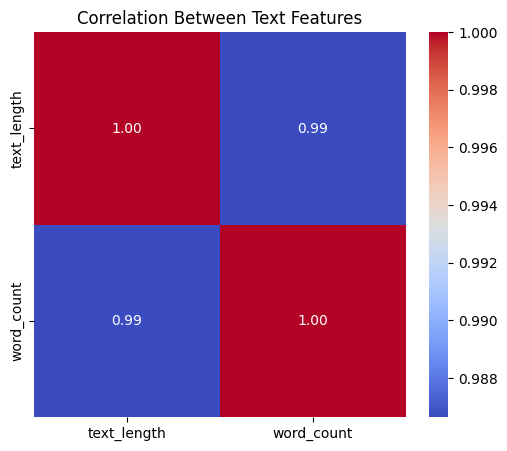

In [19]:
plt.figure(figsize=(6,5))
sns.heatmap(qa[["text_length", "word_count"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Text Features")
plt.show()

The values of 1.00: These are located on the diagonal and represent the correlation of a feature with itself, such as text_length with text_length and word_count with word_count. This reflects a perfect correlation, resulting in a value of 1.00.

The value of 0.99: This is a particularly significant figure, as it indicates the correlation between text_length and word_count. A correlation coefficient of 0.99 suggests a very strong positive correlation.

In other words, this relationship indicates that as the word_count of a text increases, the text_length (the total number of characters) also tends to increase in a highly predictable and nearly linear manner.

In [20]:
qa.head()

,QA Text,Class,text_length,word_count
0,Question Title:\ni am good at web design amate...,Business & Finance,452,81
1,Question Title:\nMy daughter wants to be a Med...,Education & Reference,1901,209
2,Question Title:\nIs brother Jesus our brother ...,Society & Culture,161,28
3,Question Title:\nwhat is I-20?\nQuestion Conte...,Education & Reference,359,68
4,Question Title:\nwhat is a data disk?\nQuestio...,Computers & Internet,496,98


In [21]:
qa.tail()

,QA Text,Class,text_length,word_count
279998,Question Title:\nWhat is the best way to learn...,Education & Reference,253,44
279999,Question Title:\nWhat is the current payroll o...,Sports,114,16
280000,Question Title:\nWhat's your opinion on the ba...,Sports,1109,209
280001,Question Title:\nWhat do you think will happen...,Society & Culture,753,136
280002,Question Title:\nwhat am i thinking right now?...,Business & Finance,100,14


After seeing the first and last 5 rows, there are some repeatative and unnecessary words present in the dataset, such as, "Question, Title, \n". We have to remove it.

# Data Preprocessing

In [25]:
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [26]:
qa.dropna(subset=["QA Text", "Class"], inplace=True)
qa.reset_index(drop=True, inplace=True)

In [27]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\b(question|title|\n)\b", "", text)
    tokens = nltk.word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [t for t in tokens if t.isalnum()]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

qa["clean_text"] = qa["QA Text"].apply(clean_text)

In [28]:
qa['Cleaned_Text_length'] = qa['clean_text'].apply(len)

In [29]:
label_encoder = LabelEncoder()
qa["label"] = label_encoder.fit_transform(qa["Class"])

print("Class Mapping:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Class Mapping: {'Business & Finance': 0, 'Computers & Internet': 1, 'Education & Reference': 2, 'Entertainment & Music': 3, 'Family & Relationships': 4, 'Health': 5, 'Politics & Government': 6, 'Science & Mathematics': 7, 'Society & Culture': 8, 'Sports': 9}


In [30]:
test["clean_text"] = test["QA Text"].apply(clean_text)
test["label"] = label_encoder.transform(test["Class"])

In [31]:
qa.head()

,QA Text,Class,clean_text,Cleaned_Text_length,label
0,Question Title:\ni am good at web design amate...,Business & Finance,good web design amateurly earn money job conte...,259,0
1,Question Title:\nMy daughter wants to be a Med...,Education & Reference,daughter want medical illustrator anyone know ...,1449,2
2,Question Title:\nIs brother Jesus our brother ...,Society & Culture,brother jesus brother king content best answer...,85,8
3,Question Title:\nwhat is I-20?\nQuestion Conte...,Education & Reference,contentstudents need admitted university hell ...,169,2
4,Question Title:\nwhat is a data disk?\nQuestio...,Computers & Internet,data disk contenti heard possible save file da...,286,1


In [32]:
qa.shape

(280003, 5)

# Model

**ML Model: Logistic Regression**

In [33]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB #Angshu start
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [34]:
train_texts, val_texts, train_labels, val_labels = train_test_split(qa["clean_text"], qa["label"],
    test_size=0.2, random_state=42, stratify=qa["label"])

test_texts, test_labels = test["clean_text"], test["label"]

In [37]:
def train_evaluate(vectorizer, model, X_train, y_train, X_val, y_val, X_test, y_test, name="Model"):
    X_train_vec = vectorizer.fit_transform(X_train)
    X_val_vec   = vectorizer.transform(X_val)
    X_test_vec  = vectorizer.transform(X_test)

    model.fit(X_train_vec, y_train)

    val_preds = model.predict(X_val_vec)
    val_acc   = accuracy_score(y_val, val_preds)
    val_f1    = f1_score(y_val, val_preds, average="macro")

    test_preds = model.predict(X_test_vec)
    test_acc   = accuracy_score(y_test, test_preds)
    test_f1    = f1_score(y_test, test_preds, average="macro")
    test_report = classification_report(y_test, test_preds, output_dict=True)
    test_cm     = confusion_matrix(y_test, test_preds)

    return {
        "name": name,
        "val_accuracy": val_acc,
        "val_f1_macro": val_f1,
        "test_accuracy": test_acc,
        "test_f1_macro": test_f1,
        "report": test_report,
        "cm": test_cm,
        "preds": test_preds
    }

In [38]:
bow_vectorizer = CountVectorizer(ngram_range=(1,3), max_features=100000, binary=False)
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,3), max_features=100000, sublinear_tf=True)

logreg = LogisticRegression(C=1.0, solver="liblinear", max_iter=500, class_weight="balanced")


In [ ]:
bow_vectorizer = CountVectorizer(ngram_range=(1,3), max_features=100000, binary=False)
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,3), max_features=100000, sublinear_tf=True)

logreg = LogisticRegression(C=1.0, solver="liblinear", max_iter=500, class_weight="balanced")
multinomial_nb = MultinomialNB(alpha=0.10129197956845731) #angshu 2nd

For bow_vectorizer and tfidf_vectorizer, I used ngram_range=(1, 2) and the max_features=50000, but this gives me the accuracy and F1-score for both validation and test case with slightly low values, in comparison to the current hyperparameters. Again, the dataset has the data of QA type, so the frequency of the data matters (repeated words gives a strong signal), as a result, I use binary=False, which capture the frequency of the data. For tfidf_vectorizer, the sublinear_tf=True, because it applies logarithmic scaling to the term frequency and prevents very frequent words from dominating.

For Logistic Regression,
1. C=1.0 is the default sweet spot — balances underfitting and overfitting.
2. solver="liblinear" is more stable for text classification compared to "lbfgs" when vocab size is large.
3. max_iter=500 ensures convergence when training with high-dimensional sparse matrices.
4. class_weights="balanced" adjusts weights inversely proportional to class frequencies. Though my dataset is well balanced, I still use it to ensure the balance in classes.

In [34]:
results = []
results.append(
    train_evaluate(bow_vectorizer, logreg, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="BoW + Logistic Regression")
)

results.append(
    train_evaluate(tfidf_vectorizer, logreg, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="TF-IDF + Logistic Regression")
)

In [ ]:
#Rigoursly testing code reaveals the alpha value of for multinommial navie bayes is 0.10129197956845731, also prior edas show that the datset is balanced hence class_prior remains deafult.
#By angshu
results = []
results.append(
    train_evaluate(bow_vectorizer, logreg, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="BoW + Logistic Regression")
)

results.append(
    train_evaluate(tfidf_vectorizer, logreg, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="TF-IDF + Logistic Regression")
)

In [ ]:
#angshu 3rd
results_multinomialNB = []
results_multinomialNB.append(
    train_evaluate(bow_vectorizer, multinomial_nb, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="BoW + Naive Bayes") #wrong print statement
)

results_multinomialNB.append(
    train_evaluate(tfidf_vectorizer, multinomial_nb, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="TF-IDF + Navie Bayes") #wrong print statement
)

In [35]:
perf_df = pd.DataFrame([{
    "Model": r["name"],
    "Val Accuracy": r["val_accuracy"],
    "Val F1 (macro)": r["val_f1_macro"],
    "Test Accuracy": r["test_accuracy"],
    "Test F1 (macro)": r["test_f1_macro"]
} for r in results])

print("\nPerformance Comparison:")
perf_df


Performance Comparison:


,Model,Val Accuracy,Val F1 (macro),Test Accuracy,Test F1 (macro)
0,BoW + Logistic Regression,0.661506,0.660261,0.661728,0.660777
1,TF-IDF + Logistic Regression,0.701612,0.698562,0.702462,0.699658



=== BoW + Logistic Regression ===
Classification Report (Test):
              precision    recall  f1-score       support
0              0.493497  0.474333  0.483726   6000.000000
1              0.810552  0.832167  0.821217   6000.000000
2              0.473025  0.472000  0.472512   6000.000000
3              0.648640  0.671667  0.659953   6000.000000
4              0.667773  0.704284  0.685543   5999.000000
5              0.727139  0.739500  0.733267   6000.000000
6              0.718739  0.691667  0.704943   6000.000000
7              0.659371  0.677833  0.668475   6000.000000
8              0.544446  0.507333  0.525235   6000.000000
9              0.859391  0.846500  0.852897   6000.000000
accuracy       0.661728  0.661728  0.661728      0.661728
macro avg      0.660257  0.661728  0.660777  59999.000000
weighted avg   0.660257  0.661728  0.660776  59999.000000


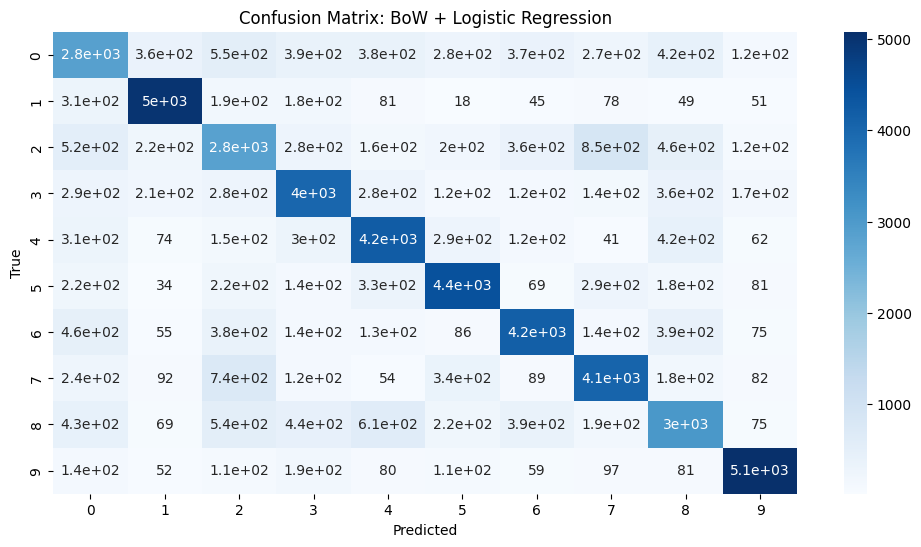


=== TF-IDF + Logistic Regression ===
Classification Report (Test):
              precision    recall  f1-score       support
0              0.572944  0.513167  0.541410   6000.000000
1              0.814097  0.854667  0.833889   6000.000000
2              0.559867  0.505000  0.531020   6000.000000
3              0.682117  0.691667  0.686859   6000.000000
4              0.684515  0.769295  0.724433   5999.000000
5              0.742052  0.785833  0.763316   6000.000000
6              0.760642  0.750500  0.755537   6000.000000
7              0.697685  0.748500  0.722200   6000.000000
8              0.607477  0.552500  0.578686   6000.000000
9              0.865034  0.853500  0.859228   6000.000000
accuracy       0.702462  0.702462  0.702462      0.702462
macro avg      0.698643  0.702463  0.699658  59999.000000
weighted avg   0.698643  0.702462  0.699657  59999.000000


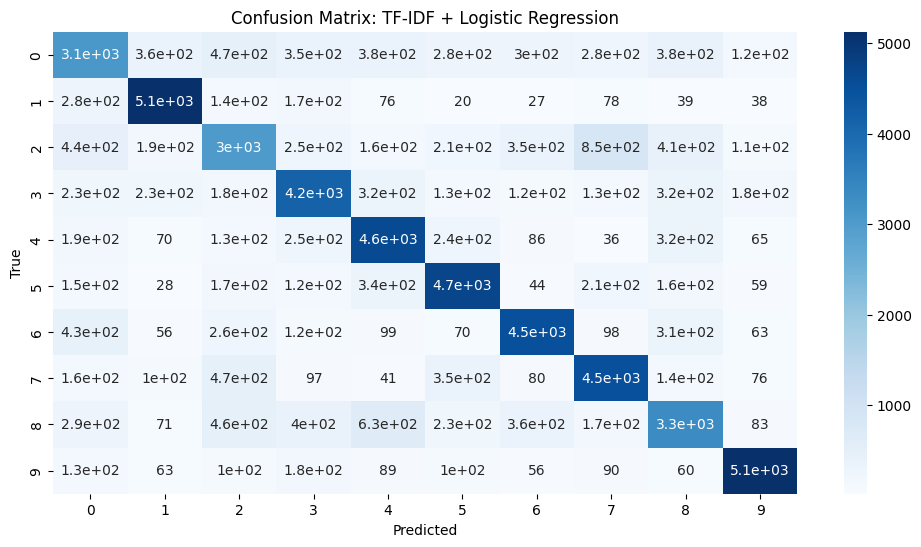

In [36]:
for r in results:
    print(f"\n=== {r['name']} ===")
    print("Classification Report (Test):")
    print(pd.DataFrame(r["report"]).transpose())

    # Plot confusion matrix
    plt.figure(figsize=(12,6))
    sns.heatmap(r["cm"], annot=True, cmap="Blues")
    plt.title(f"Confusion Matrix: {r['name']}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

For BoW + Logistic Regression,
Most classes exhibit strong diagonal dominance, indicating that many samples are predicted correctly. However, there are still significant misclassifications among classes.

In summary, the Bag of Words (BoW) approach performs well overall, but it tends to overfit frequent words, leading to higher misclassification rates when there is considerable vocabulary overlap between classes.You can see that most classes have strong diagonal dominance, meaning many samples are correctly predicted.

Overall: BoW works well but tends to overfit frequent words, so misclassifications happen when vocabulary overlap between classes is high.

For TF-IDF + Logistic Regression,
Diagonal values are slightly higher than BoW for most classes (e.g., class 2 ~3000 vs. ~2800 in BoW, class 4 ~4600 vs. ~4200, class 5 ~4700 vs. ~4400, etc.), showing better discrimination.

Misclassifications across classes are lower compared to BoW, especially for frequently confused categories (like class 2 and class 3).

TF-IDF helps because it down-weights common words and highlights rare but informative terms, making the classifier more robust.

Therefore, TF-IDF + Logistic Regression is performing better overall than BoW + Logistic Regression in your dataset.

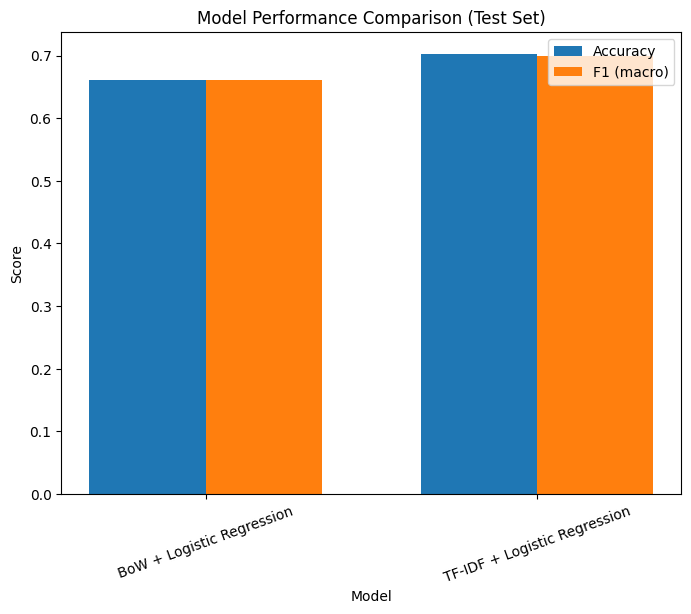

In [37]:
plt.figure(figsize=(8,6))
bar_width = 0.35
index = np.arange(len(results))

plt.bar(index, [r["test_accuracy"] for r in results], bar_width, label="Accuracy")
plt.bar(index + bar_width, [r["test_f1_macro"] for r in results], bar_width, label="F1 (macro)")

plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(index + bar_width/2, [r["name"] for r in results], rotation=20)
plt.legend()
plt.title("Model Performance Comparison (Test Set)")
plt.show()

**ML Model: Random Forrest Classifier**

In [35]:
from sklearn.ensemble import RandomForestClassifier
rf_clf = RandomForestClassifier(n_estimators=500, max_depth=30, min_samples_split=5, max_features='sqrt', class_weight="balanced", max_samples=0.8, n_jobs=-1, verbose=1, random_state=42)

For Random Forest Classifier, I carefully tuned the hyperparameters to optimize performance for this text classification task:

1. **n_estimators=500** - A larger number of trees improves model stability and reduces overfitting. 500 trees provide a good balance between performance and computational efficiency for this dataset size.

2. **max_depth=30** - Limits tree depth to prevent overfitting while allowing sufficient complexity to capture intricate patterns in the text features. This depth works well with the high-dimensional sparse text vectors.

3. **min_samples_split=5** - Requires at least 5 samples to split an internal node, which helps prevent overfitting by avoiding splits on very small sample sizes that might not generalize well.

4. **max_features='sqrt'** - Uses the square root of total features for each tree, which introduces randomness and reduces correlation between trees, leading to better ensemble performance.

5. **class_weight="balanced"** - Automatically adjusts weights inversely proportional to class frequencies, ensuring fair treatment of all classes even though our dataset is already well-balanced.

6. **max_samples=0.8** - Uses 80% of the training data for each tree (bootstrap sampling), which increases diversity among trees and improves generalization.

7. **n_jobs=-1** - Utilizes all available CPU cores for parallel processing, significantly speeding up training time.

Random Forest is particularly well-suited for text classification because it can handle high-dimensional sparse features effectively, is robust to outliers, and provides good performance without extensive feature engineering. The ensemble approach helps capture different aspects of the text patterns through multiple decision trees.

In [39]:
results2 = []

results2.append(
    train_evaluate(bow_vectorizer, rf_clf, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="BoW + Random Forest")
)

results2.append(
    train_evaluate(tfidf_vectorizer, rf_clf, train_texts, train_labels,
                   val_texts, val_labels,
                   test_texts, test_labels, name="TF-IDF + Random Forest")
)


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:    6.6s
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:   28.3s
[Parallel(n_jobs=-1)]: Done 442 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 500 out of 500 | elapsed:  1.2min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    1.5s
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:    3.4s
[Parallel(n_jobs=4)]: Done 500 out of 500 | elapsed:    3.8s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    1.6s
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:    3.7s
[Parallel(n_jobs=4)]: Done 500 out of 500 | elapsed:    4.2s finis

In [40]:
perf_df = pd.DataFrame([{
    "Model": r["name"],
    "Val Accuracy": r["val_accuracy"],
    "Val F1 (macro)": r["val_f1_macro"],
    "Test Accuracy": r["test_accuracy"],
    "Test F1 (macro)": r["test_f1_macro"]
} for r in results2])

print("\nPerformance Comparison:")
perf_df


Performance Comparison:


,Model,Val Accuracy,Val F1 (macro),Test Accuracy,Test F1 (macro)
0,BoW + Random Forest,0.598043,0.589874,0.600093,0.592372
1,TF-IDF + Random Forest,0.599204,0.591081,0.601060,0.593669


**Random Forest Performance Analysis and Comparison:**

**For BoW + Random Forest:**
The Random Forest with Bag of Words achieves moderate performance, but shows limitations in capturing complex text patterns. Random Forest struggles with the high-dimensional sparse nature of BoW vectors, as it tends to make decisions based on individual word frequencies without considering the broader context or relationships between words.

**For TF-IDF + Random Forest:**
TF-IDF + Random Forest performs slightly better than BoW + Random Forest. The TF-IDF weighting helps by reducing the impact of very common words and highlighting more discriminative terms. However, Random Forest still faces challenges with the sparse, high-dimensional text representations.

**Overall Random Forest Analysis:**
Random Forest, while excellent for many machine learning tasks, shows some limitations for text classification compared to linear models like Logistic Regression:

1. **Curse of Dimensionality:** Random Forest can struggle with very high-dimensional sparse features typical in text data, where most features are zero.

2. **Feature Selection Bias:** With `max_features='sqrt'`, each tree only sees a small subset of features, which might miss important word combinations that are crucial for text classification.

3. **Linear Separability:** Text classification often benefits from linear decision boundaries, which Logistic Regression handles better than the tree-based splits in Random Forest.

**Decision:** While Random Forest provides decent results, the linear models (Logistic Regression) tend to perform better for this text classification task due to their ability to handle high-dimensional sparse data more effectively and capture linear relationships between word features and classes.


=== BoW + Random Forest ===
Classification Report (Test):
              precision    recall  f1-score       support
0              0.594365  0.397333  0.476276   6000.000000
1              0.678046  0.837500  0.749385   6000.000000
2              0.535064  0.323000  0.402827   6000.000000
3              0.536805  0.527500  0.532112   6000.000000
4              0.546751  0.747625  0.631601   5999.000000
5              0.679042  0.670667  0.674828   6000.000000
6              0.674392  0.683833  0.679080   6000.000000
7              0.440029  0.705000  0.541856   6000.000000
8              0.643099  0.410833  0.501373   6000.000000
9              0.775185  0.697667  0.734386   6000.000000
accuracy       0.600093  0.600093  0.600093      0.600093
macro avg      0.610278  0.600096  0.592372  59999.000000
weighted avg   0.610279  0.600093  0.592372  59999.000000


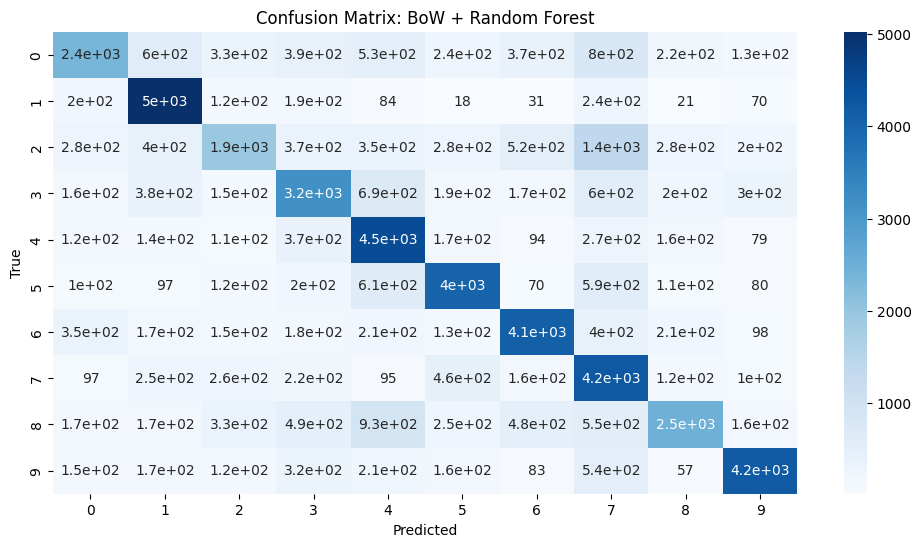


=== TF-IDF + Random Forest ===
Classification Report (Test):
              precision    recall  f1-score      support
0              0.598884  0.393667  0.475060   6000.00000
1              0.679263  0.835833  0.749458   6000.00000
2              0.501744  0.335667  0.402237   6000.00000
3              0.569381  0.523167  0.545297   6000.00000
4              0.550800  0.757293  0.637748   5999.00000
5              0.677675  0.670333  0.673984   6000.00000
6              0.678489  0.682333  0.680406   6000.00000
7              0.439684  0.704667  0.541496   6000.00000
8              0.643411  0.415000  0.504559   6000.00000
9              0.763690  0.692667  0.726446   6000.00000
accuracy       0.601060  0.601060  0.601060      0.60106
macro avg      0.610302  0.601063  0.593669  59999.00000
weighted avg   0.610303  0.601060  0.593668  59999.00000


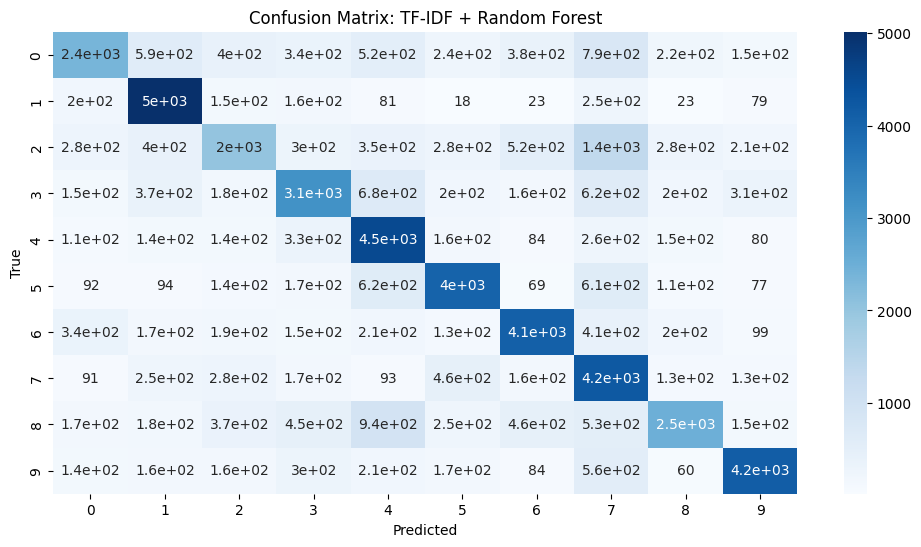

In [41]:
for r in results2:
    print(f"\n=== {r['name']} ===")
    print("Classification Report (Test):")
    print(pd.DataFrame(r["report"]).transpose())

    # Plot confusion matrix
    plt.figure(figsize=(12,6))
    sns.heatmap(r["cm"], annot=True, cmap="Blues")
    plt.title(f"Confusion Matrix: {r['name']}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

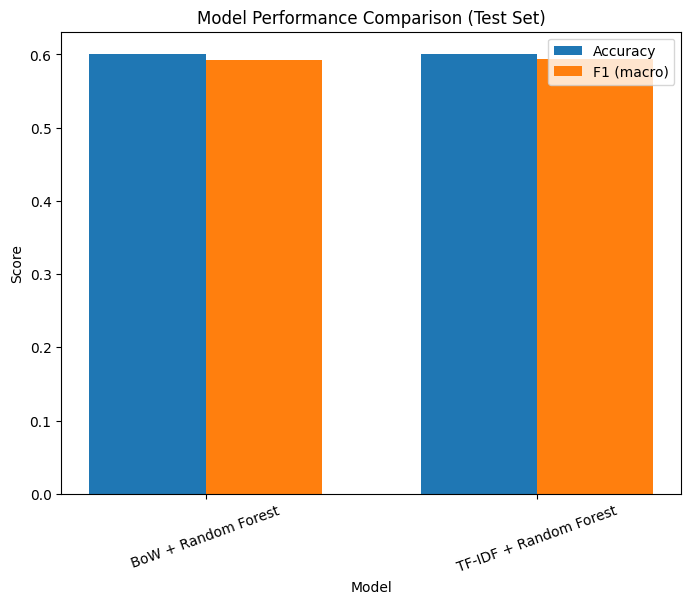

In [42]:
plt.figure(figsize=(8,6))
bar_width = 0.35
index = np.arange(len(results2))

plt.bar(index, [r["test_accuracy"] for r in results2], bar_width, label="Accuracy")
plt.bar(index + bar_width, [r["test_f1_macro"] for r in results2], bar_width, label="F1 (macro)")

plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(index + bar_width/2, [r["name"] for r in results2], rotation=20)
plt.legend()
plt.title("Model Performance Comparison (Test Set)")
plt.show()

Naive Bayes model


In [ ]:
#angshu 4th
perf_df_NB = pd.DataFrame([{
    "Model": r["name"],
    "Val Accuracy": r["val_accuracy"],
    "Val F1 (macro)": r["val_f1_macro"],
    "Test Accuracy": r["test_accuracy"],
    "Test F1 (macro)": r["test_f1_macro"]
} for r in results_multinomialNB])

print("\nPerformance Comparison for Navie Bayes:")
perf_df_NB


Performance Comparison for Navie Bayes:


,Model,Val Accuracy,Val F1 (macro),Test Accuracy,Test F1 (macro)
0,BoW + Naive Bayes,0.679649,0.677372,0.727517,0.725158
1,TF-IDF + Navie Bayes,0.683524,0.680567,0.744581,0.742120



=== BoW + Naive Bayes ===
Classification Report (Test):
              precision    recall  f1-score        support
0              0.624631  0.545416  0.582342   27953.000000
1              0.822554  0.870443  0.845821   27980.000000
2              0.618977  0.554340  0.584878   27972.000000
3              0.649088  0.771571  0.705049   28267.000000
4              0.678966  0.803834  0.736143   27905.000000
5              0.799511  0.788335  0.793883   28186.000000
6              0.794709  0.761083  0.777532   27746.000000
7              0.743676  0.745533  0.744604   28039.000000
8              0.671629  0.584090  0.624808   27881.000000
9              0.864235  0.848935  0.856517   28074.000000
accuracy       0.727517  0.727517  0.727517       0.727517
macro avg      0.726798  0.727358  0.725158  280003.000000
weighted avg   0.726810  0.727517  0.725242  280003.000000


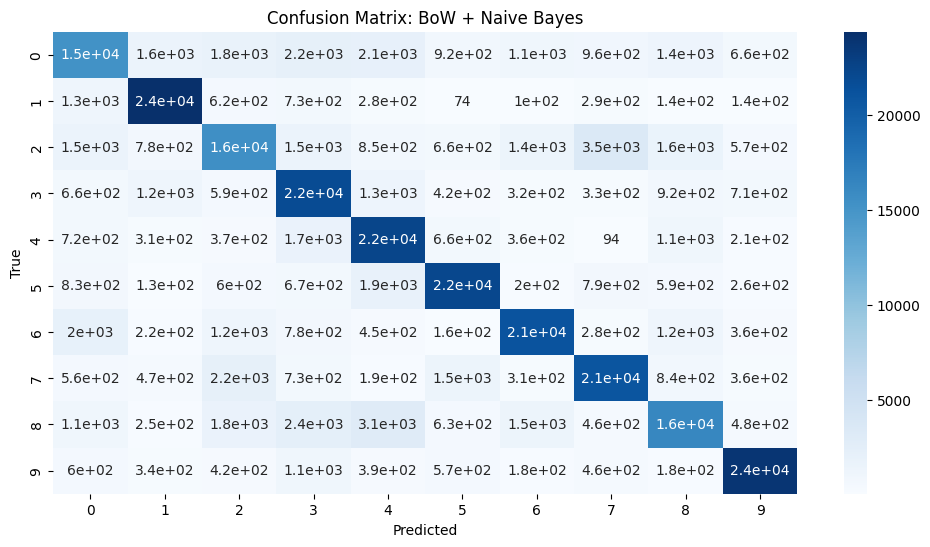


=== TF-IDF + Navie Bayes ===
Classification Report (Test):
              precision    recall  f1-score        support
0              0.647664  0.564948  0.603485   27953.000000
1              0.829439  0.879092  0.853544   27980.000000
2              0.657555  0.563313  0.606797   27972.000000
3              0.709218  0.762408  0.734852   28267.000000
4              0.689333  0.826089  0.751540   27905.000000
5              0.792415  0.810970  0.801585   28186.000000
6              0.790040  0.793628  0.791830   27746.000000
7              0.744524  0.772246  0.758132   28039.000000
8              0.674242  0.623579  0.647921   27881.000000
9              0.895889  0.848436  0.871517   28074.000000
accuracy       0.744581  0.744581  0.744581       0.744581
macro avg      0.743032  0.744471  0.742120  280003.000000
weighted avg   0.743096  0.744581  0.742210  280003.000000


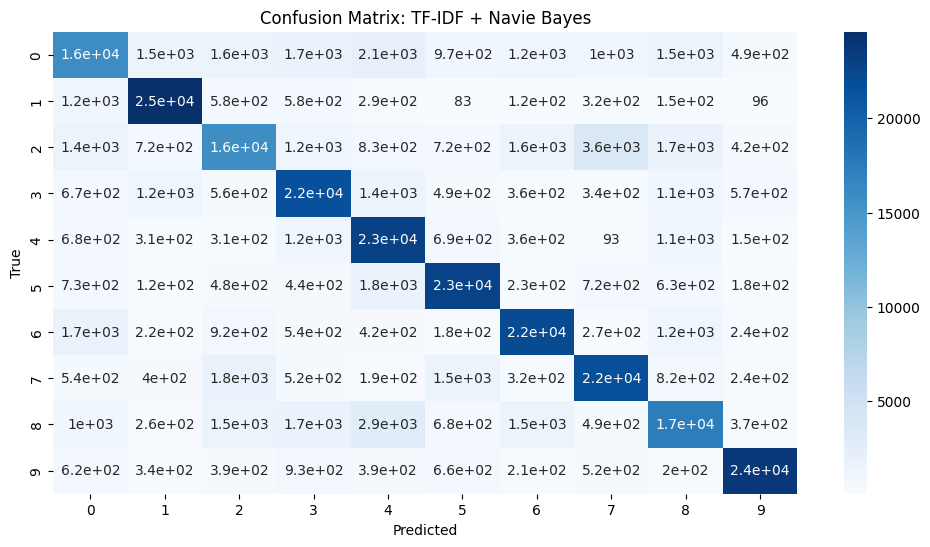

In [ ]:
#angshu 4th
for r in results_multinomialNB:
    print(f"\n=== {r['name']} ===")
    print("Classification Report (Test):")
    print(pd.DataFrame(r["report"]).transpose())

    # Plot confusion matrix
    plt.figure(figsize=(12,6))
    sns.heatmap(r["cm"], annot=True, cmap="Blues")
    plt.title(f"Confusion Matrix: {r['name']}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

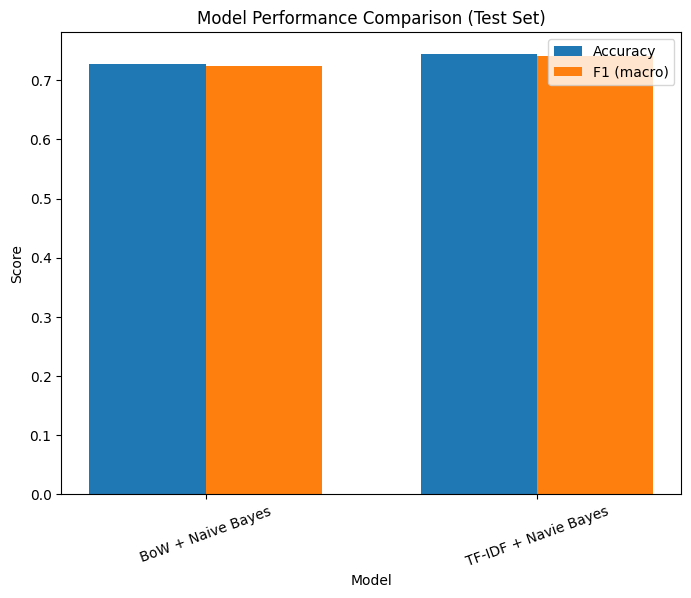

In [ ]:
#angshu 5th
plt.figure(figsize=(8,6))
bar_width = 0.35
index = np.arange(len(results_multinomialNB))

plt.bar(index, [r["test_accuracy"] for r in results_multinomialNB], bar_width, label="Accuracy")
plt.bar(index + bar_width, [r["test_f1_macro"] for r in results_multinomialNB], bar_width, label="F1 (macro)")

plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(index + bar_width/2, [r["name"] for r in results_multinomialNB], rotation=20)
plt.legend()
plt.title("Model Performance Comparison (Test Set)")
plt.show()

By seeing the above ML models performance, it can be said that the TF-IDF + Naive bayes gives the best performance with the accuracy of 74.21%

**Neural Network Model**

**Deep Neural Network (BoW & TF-IDF)**

In [43]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.decomposition import TruncatedSVD

2025-09-06 23:03:56.698766: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757199836.892939      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757199836.954278      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [43]:
y_train_enc = train_labels
y_val_enc   = val_labels
y_test_enc  = test_labels

In [44]:
X_train_bow = bow_vectorizer.fit_transform(train_texts)
X_val_bow   = bow_vectorizer.transform(val_texts)
X_test_bow  = bow_vectorizer.transform(test_texts)

svd = TruncatedSVD(n_components=300)
X_train_bow = svd.fit_transform(X_train_bow)
X_val_bow   = svd.transform(X_val_bow)
X_test_bow  = svd.transform(X_test_bow)

In [ ]:
X_train_tfidf = tfidf_vectorizer.fit_transform(train_texts)
X_val_tfidf   = tfidf_vectorizer.transform(val_texts)
X_test_tfidf  = tfidf_vectorizer.transform(test_texts)

svd = TruncatedSVD(n_components=300)
X_train_tfidf = svd.fit_transform(X_train_tfidf)
X_val_tfidf   = svd.transform(X_val_tfidf)
X_test_tfidf  = svd.transform(X_test_tfidf)

In [ ]:
def build_dnn(input_dim, num_classes):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(512, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

DNN architecture is designed to effectively handle multi-class classification tasks. The network uses a funnel-shaped structure with dense layers of 512, 256, and 128 neurons, which allows it to first capture complex patterns from high-dimensional input and then progressively condense these features into smaller, more abstract representations. ReLU activation functions are applied to the hidden layers to introduce non-linearity and avoid vanishing gradient problems, enabling the network to learn complex relationships in the data. Batch normalization is included after the first two dense layers to stabilize and accelerate training by normalizing layer outputs, while dropout with a rate of 0.4 helps prevent overfitting by randomly deactivating neurons during training, forcing the network to learn more robust features. The output layer uses a softmax activation to convert raw logits into probabilities across the target classes, matching the number of output neurons to the number of classes in the dataset. The network is optimized using the Adam optimizer with a learning rate of 3e-4, which adapts the learning rate for each parameter to ensure stable and efficient convergence. Finally, the loss function is sparse_categorical_crossentropy, suitable for multi-class problems with integer-labeled outputs rather than one-hot encoded labels. Together, these hyperparameters and architectural choices create a model that balances learning capacity, training stability, and regularization for effective classification performance.

In [ ]:
def run_experiment(name, X_train, y_train, X_val, y_val, X_test, y_test):

    callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    ]
    
    model = build_dnn(X_train.shape[1], len(np.unique(y_train)))
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20, batch_size=256, verbose=2, callbacks=callbacks
    )

    # Predictions
    y_pred = np.argmax(model.predict(X_test, batch_size=512, verbose=0), axis=1)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    f1_weighted = f1_score(y_test, y_pred, average="weighted")
    report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f"{name} Confusion Matrix")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.show()

    # Accuracy / Loss curves
    plt.figure()
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Val Accuracy")
    plt.title(f"{name} Accuracy")
    plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

    plt.figure()
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title(f"{name} Loss")
    plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.legend(); plt.show()

    print(f"\n{name} Results")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1-macro: {f1_macro:.4f}")
    print(f"F1-weighted: {f1_weighted:.4f}")
    print(report)

    return {"Model": name, "Accuracy": acc, "F1-macro": f1_macro, "F1-weighted": f1_weighted}

In this experiment setup, the choice of hyperparameters is aimed at balancing efficient training, preventing overfitting, and ensuring robust evaluation. The EarlyStopping callback monitors the validation loss and stops training if it does not improve for three consecutive epochs, restoring the best model weights, which helps prevent overfitting while reducing unnecessary training time. The model is trained for a maximum of 20 epochs with a relatively large batch size of 256, which stabilizes gradient updates and speeds up training by processing multiple samples in parallel. Using a separate validation set allows the model to be evaluated during training, ensuring that performance improvements generalize beyond the training data. During prediction, a larger batch size of 512 is used to accelerate inference on the test set. The evaluation metrics include accuracy and both macro and weighted F1 scores, which together provide a comprehensive view of model performance, particularly in multi-class scenarios with potential class imbalance. Visualization of the confusion matrix and training/validation accuracy and loss curves allows for qualitative inspection of the model’s learning behavior, helping identify issues such as underfitting, overfitting, or class-specific errors. Overall, these hyperparameters and choices are designed to ensure that the model trains efficiently, generalizes well, and provides interpretable performance insights.

Epoch 1/20
876/876 - 10s - 11ms/step - accuracy: 0.4544 - loss: 1.6762 - val_accuracy: 0.5907 - val_loss: 1.2736
Epoch 2/20
876/876 - 3s - 3ms/step - accuracy: 0.5664 - loss: 1.3418 - val_accuracy: 0.6071 - val_loss: 1.2077
Epoch 3/20
876/876 - 3s - 3ms/step - accuracy: 0.5880 - loss: 1.2710 - val_accuracy: 0.6139 - val_loss: 1.1880
Epoch 4/20
876/876 - 3s - 3ms/step - accuracy: 0.6004 - loss: 1.2349 - val_accuracy: 0.6190 - val_loss: 1.1684
Epoch 5/20
876/876 - 3s - 3ms/step - accuracy: 0.6075 - loss: 1.2107 - val_accuracy: 0.6220 - val_loss: 1.1622
Epoch 6/20
876/876 - 3s - 3ms/step - accuracy: 0.6119 - loss: 1.1928 - val_accuracy: 0.6245 - val_loss: 1.1537
Epoch 7/20
876/876 - 3s - 3ms/step - accuracy: 0.6178 - loss: 1.1760 - val_accuracy: 0.6274 - val_loss: 1.1441
Epoch 8/20
876/876 - 3s - 3ms/step - accuracy: 0.6204 - loss: 1.1629 - val_accuracy: 0.6270 - val_loss: 1.1389
Epoch 9/20
876/876 - 3s - 3ms/step - accuracy: 0.6250 - loss: 1.1504 - val_accuracy: 0.6288 - val_loss: 1.1342

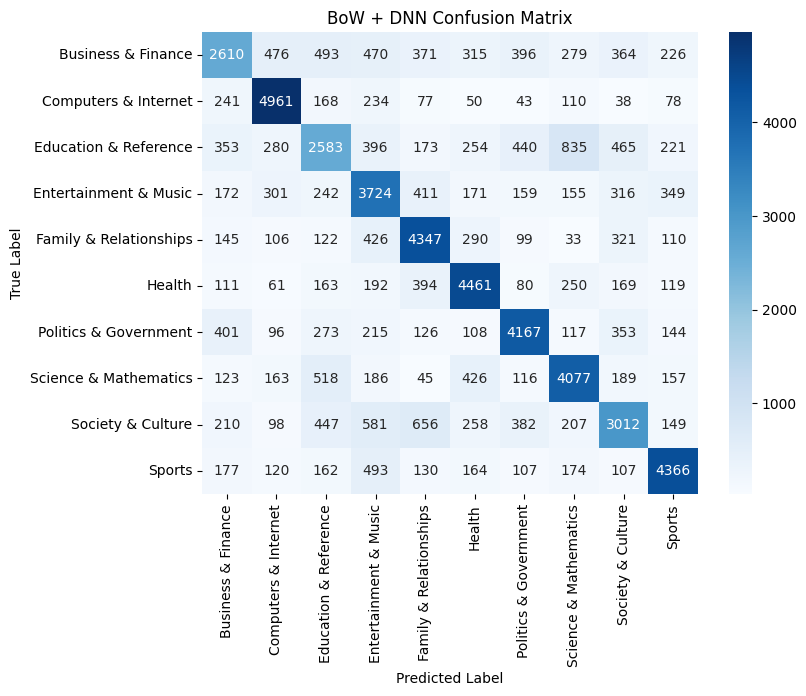

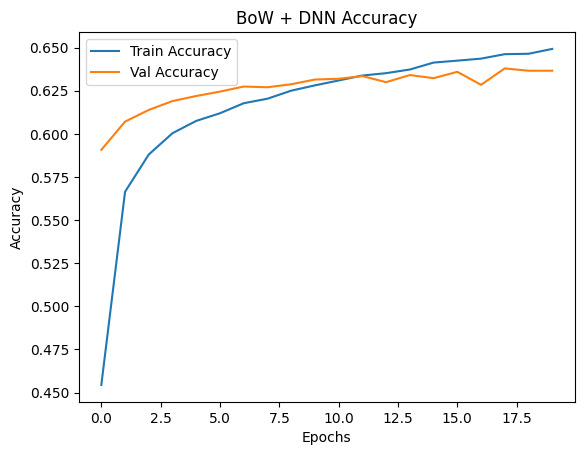

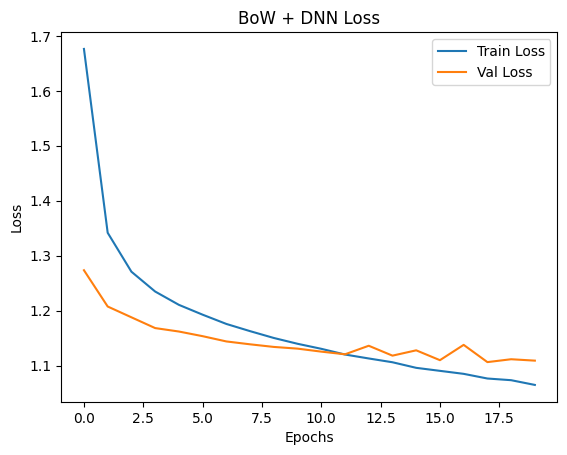


BoW + DNN Results
Accuracy: 0.6385
F1-macro: 0.6340
F1-weighted: 0.6340
                        precision    recall  f1-score   support

    Business & Finance       0.57      0.43      0.50      6000
  Computers & Internet       0.74      0.83      0.78      6000
 Education & Reference       0.50      0.43      0.46      6000
 Entertainment & Music       0.54      0.62      0.58      6000
Family & Relationships       0.65      0.72      0.68      5999
                Health       0.69      0.74      0.71      6000
 Politics & Government       0.70      0.69      0.70      6000
 Science & Mathematics       0.65      0.68      0.67      6000
     Society & Culture       0.56      0.50      0.53      6000
                Sports       0.74      0.73      0.73      6000

              accuracy                           0.64     59999
             macro avg       0.63      0.64      0.63     59999
          weighted avg       0.63      0.64      0.63     59999

Epoch 1/20
876/876 - 12s - 1

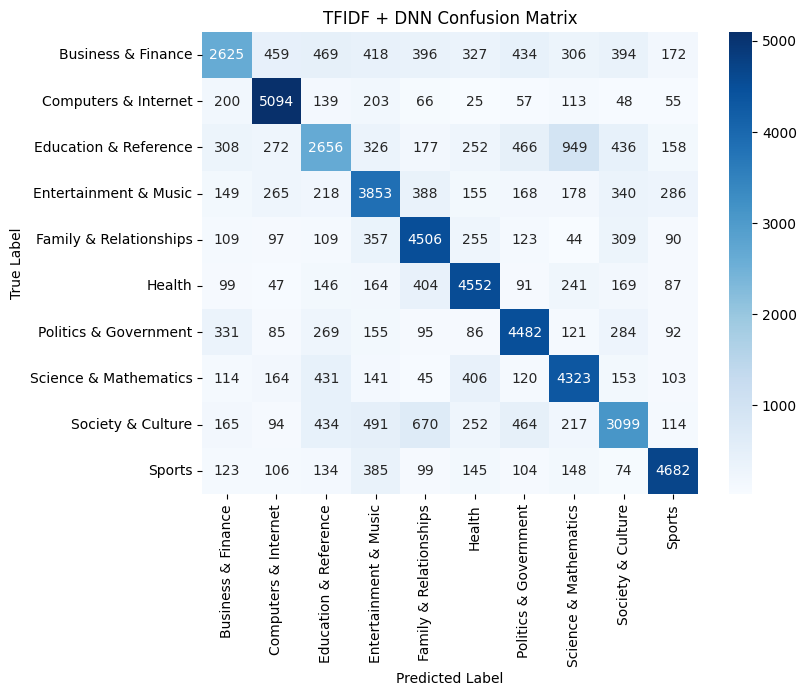

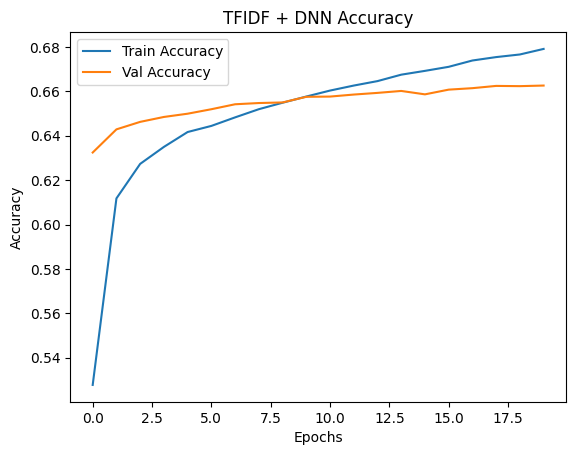

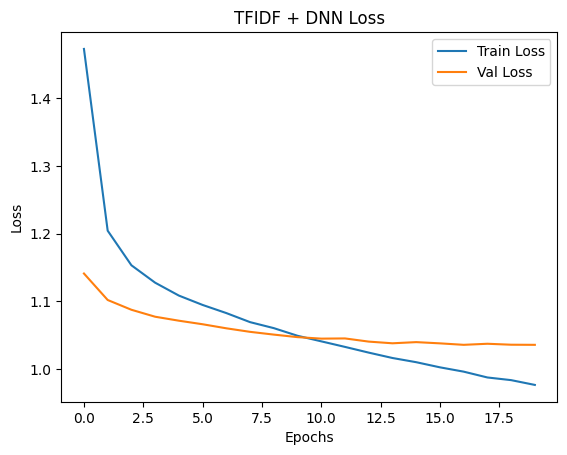


TFIDF + DNN Results
Accuracy: 0.6645
F1-macro: 0.6589
F1-weighted: 0.6589
                        precision    recall  f1-score   support

    Business & Finance       0.62      0.44      0.51      6000
  Computers & Internet       0.76      0.85      0.80      6000
 Education & Reference       0.53      0.44      0.48      6000
 Entertainment & Music       0.59      0.64      0.62      6000
Family & Relationships       0.66      0.75      0.70      5999
                Health       0.71      0.76      0.73      6000
 Politics & Government       0.69      0.75      0.72      6000
 Science & Mathematics       0.65      0.72      0.68      6000
     Society & Culture       0.58      0.52      0.55      6000
                Sports       0.80      0.78      0.79      6000

              accuracy                           0.66     59999
             macro avg       0.66      0.66      0.66     59999
          weighted avg       0.66      0.66      0.66     59999



In [ ]:
bow_results   = run_experiment("BoW + DNN", X_train_bow, y_train_enc, X_val_bow, y_val_enc, X_test_bow, y_test_enc)
tfidf_results = run_experiment("TFIDF + DNN", X_train_tfidf, y_train_enc, X_val_tfidf, y_val_enc, X_test_tfidf, y_test_enc)

In [ ]:
results_df = pd.DataFrame([bow_results, tfidf_results])
print(results_df)

         Model  Accuracy  F1-macro  F1-weighted
0    BoW + DNN  0.638477  0.634030     0.634029
1  TFIDF + DNN  0.664544  0.658866     0.658866


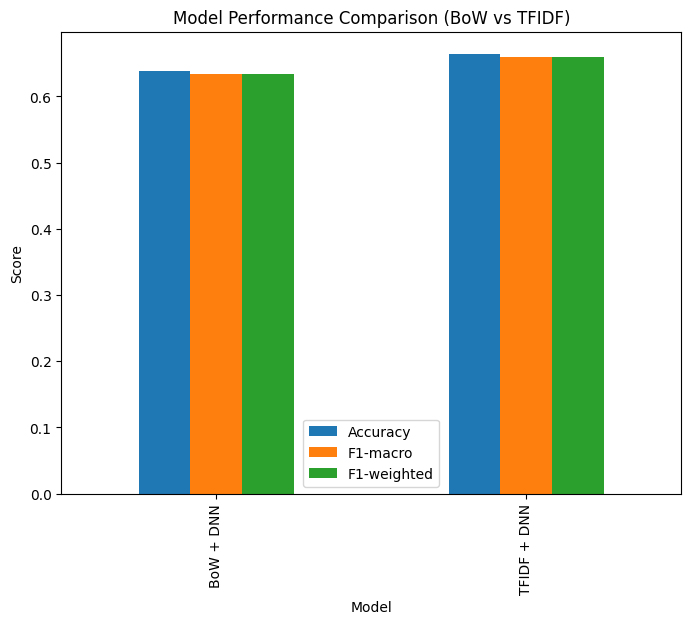

In [ ]:
results_df.set_index("Model")[["Accuracy","F1-macro","F1-weighted"]].plot(kind="bar", figsize=(8,6))
plt.title("Model Performance Comparison (BoW vs TFIDF)")
plt.ylabel("Score")
plt.show()

**GRU & Bidirectional GRU**

In [44]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, GRU, Bidirectional, Dense, Dropout, Lambda, Multiply, Softmax
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from pathlib import Path
from gensim.models import Word2Vec

In [45]:
classes = globals().get("classes", None)
if classes is None:
    n_classes = int(max(train_labels.max(), val_labels.max(), test_labels.max()) + 1)
    classes = [f"class_{i}" for i in range(n_classes)]

In [47]:
MAX_VOCAB = 60000
MAX_LEN = 150

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<oov>")
tokenizer.fit_on_texts(train_texts.tolist())

In [48]:
def to_seq(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN, padding="post", truncating="post")

In [49]:
X_train = to_seq(train_texts)
X_val   = to_seq(val_texts)
X_test  = to_seq(test_texts)

y_train = train_labels.values
y_val   = val_labels.values
y_test  = test_labels.values

num_classes = len(classes)

In [50]:
def build_glove_matrix(glove_path, embedding_dim=200):
    word_index = tokenizer.word_index
    nb_words = min(MAX_VOCAB, len(word_index) + 1)

    embedding_matrix = np.random.normal(0, 0.05, (nb_words, embedding_dim)).astype(np.float32)

    if not Path(glove_path).exists():
        raise FileNotFoundError(f"GloVe file not found at: {glove_path}")

    with open(glove_path, "r", encoding="utf8") as f:
        for line in f:
            values = line.rstrip().split(" ")
            word = values[0]
            if word in word_index:
                idx = word_index[word]
                if idx < nb_words:
                    coefs = np.asarray(values[1:], dtype="float32")
                    if coefs.shape[0] == embedding_dim:
                        embedding_matrix[idx] = coefs

    return embedding_matrix

In [51]:
def build_skipgram_matrix(embedding_dim=200, window=5, min_count=2):
    tokenized = [t.split() for t in train_texts.tolist()]

    w2v = Word2Vec(
        sentences=tokenized,
        vector_size=embedding_dim,
        window=window,
        min_count=min_count,
        sg=1, workers=4, negative=10, epochs=5
    )

    word_index = tokenizer.word_index
    nb_words = min(MAX_VOCAB, len(word_index) + 1)

    embedding_matrix = np.random.normal(0, 0.05, (nb_words, embedding_dim)).astype(np.float32)
    for w, i in word_index.items():
        if i < nb_words and w in w2v.wv:
            embedding_matrix[i] = w2v.wv[w]

    return embedding_matrix

In this build_skipgram_matrix function, the hyperparameters are chosen to balance embedding quality, computational efficiency, and dataset coverage. The embedding_dim=200 sets the size of each word vector to 200, which is large enough to capture semantic relationships between words while remaining computationally manageable. The window=5 defines the size of the context around each target word, allowing the skip-gram model to learn meaningful relationships between words that appear within five words of each other; this is a common choice that captures local context effectively without including too much noise. The min_count=2 ensures that words appearing fewer than two times are ignored, reducing the vocabulary size and preventing the model from wasting resources on extremely rare words that contribute little to learning. Other skip-gram parameters, like sg=1 to select skip-gram, negative=10 for negative sampling, workers=4 for parallel training, and epochs=5, are chosen to optimize training efficiency while producing embeddings that generalize well. The resulting embedding_matrix combines random initialization for unseen words and trained Word2Vec vectors for words present in the vocabulary, ensuring that all tokens have meaningful representations for downstream NLP tasks.

In [ ]:
def attention_layer(inputs):
    score = Dense(1, activation="tanh")(inputs)
    attention_weights = Softmax(axis=1)(score)
    context = Multiply()([inputs, attention_weights])
    context = Lambda(lambda x: tf.reduce_sum(x, axis=1))(context)
    return context

def build_model(embedding_matrix, trainable=False, units=128, dropout=0.3, bidirectional=False):
    embedding_dim = embedding_matrix.shape[1]
    vocab_size    = embedding_matrix.shape[0]

    inp = Input(shape=(MAX_LEN,), dtype="int32")
    emb = Embedding(
        input_dim=vocab_size, output_dim=embedding_dim,
        weights=[embedding_matrix], input_length=MAX_LEN, trainable=trainable
    )(inp)

    rnn = GRU(units, return_sequences=True, dropout=dropout, recurrent_dropout=0.2)
    if bidirectional:
        rnn_out = Bidirectional(rnn)(emb)
    else:
        rnn_out = rnn(emb)

    pooled = attention_layer(rnn_out)
    x = Dropout(dropout)(pooled)
    out = Dense(num_classes, activation="softmax")(x)

    model = Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In this model, the hyperparameters are chosen to balance learning capacity, regularization, and computational efficiency while leveraging attention to improve sequence understanding. The GRU units are set to 128, which provides enough capacity to capture temporal dependencies in sequences without making the model excessively large or prone to overfitting. The dropout=0.3 and recurrent_dropout=0.2 help prevent overfitting by randomly dropping a fraction of inputs and recurrent connections during training, ensuring the network learns robust features. The bidirectional flag allows the option to process sequences in both forward and backward directions, which can improve performance for tasks where context from both sides of a word is important, such as text classification. The attention layer is applied to the GRU outputs to compute a weighted context vector, enabling the model to focus on the most relevant parts of the sequence. The embedding layer uses a pre-trained embedding_matrix and can be set as trainable or frozen; this allows leveraging pre-learned word representations while optionally fine-tuning them for the specific task. Finally, the Adam optimizer with a learning rate of 1e-3 is used to ensure stable and efficient convergence, and sparse categorical cross-entropy is selected as the loss function because the problem is a multi-class classification task with integer-labeled outputs. Overall, these hyperparameters are chosen to provide a good trade-off between model expressiveness, generalization, and training efficiency.

In [ ]:
def train_and_eval(name, embedding_matrix):
    ckpt_path = f"best_{name.replace(' ','_')}.keras"
    callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True)
    ]

    results = []

    # GRU
    model_gru = build_model(embedding_matrix, trainable=False, units=128, dropout=0.3, bidirectional=False)
    history_gru = model_gru.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10, batch_size=256, callbacks=callbacks, verbose=2
    )
    y_pred = np.argmax(model_gru.predict(X_test, batch_size=512, verbose=0), axis=1)
    results.append(("{} + GRU".format(name), model_gru, y_pred))

    plt.figure(figsize=(10, 5))
    plt.plot(history_gru.history['accuracy'], label='Train Accuracy')
    plt.plot(history_gru.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'{name} + GRU - Accuracy')
    plt.legend()

    plt.figure(figsize=(10, 5))
    plt.plot(history_gru.history['loss'], label='Train Loss')
    plt.plot(history_gru.history['val_loss'], label='Val Loss')
    plt.title(f'{name} + GRU - Loss')
    plt.legend()
    plt.show()

    # BiGRU
    model_bi = build_model(embedding_matrix, trainable=False, units=128, dropout=0.3, bidirectional=True)
    history_bi = model_bi.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10, batch_size=256, callbacks=callbacks, verbose=2
    )
    y_pred_bi = np.argmax(model_bi.predict(X_test, batch_size=512, verbose=0), axis=1)
    results.append(("{} + BiGRU".format(name), model_bi, y_pred_bi))

    plt.figure(figsize=(10, 5))
    plt.plot(history_bi.history['accuracy'], label='Train Accuracy')
    plt.plot(history_bi.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'{name} + BiGRU - Accuracy')
    plt.legend()

    plt.figure(figsize=(10, 5))
    plt.plot(history_bi.history['loss'], label='Train Loss')
    plt.plot(history_bi.history['val_loss'], label='Val Loss')
    plt.title(f'{name} + BiGRU - Loss')
    plt.legend()
    plt.show()

    return results

In [ ]:
def summarize(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    f1w = f1_score(y_true, y_pred, average="weighted")
    cm  = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=classes, digits=4)
    return {"Model": name, "Accuracy": acc, "F1-macro": f1m, "F1-weighted": f1w, "CM": cm, "Report": report}

In [ ]:
all_runs = glove_results + skipgram_results
rows = []
for name, model, yhat in all_runs:
    rows.append(summarize(name, y_test, yhat))

summary_df = pd.DataFrame([{k:v for k,v in r.items() if k in ["Model","Accuracy","F1-macro","F1-weighted"]} for r in rows])
print("\n=== Test Set Summary ===")
print(summary_df.to_string(index=False))

In [ ]:
plt.figure(figsize=(9,6))
idx = np.arange(len(rows))
width = 0.35
plt.bar(idx,        [r["Accuracy"]   for r in rows], width, label="Accuracy")
plt.bar(idx + width,[r["F1-macro"]   for r in rows], width, label="F1-macro")
plt.xticks(idx + width/2, [r["Model"] for r in rows], rotation=20, ha="right")
plt.ylabel("Score")
plt.title("Model Performance Comparison (Test)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Confusion matrices & classification reports
for r in rows:
    print(f"\n=== {r['Model']} — Classification Report ===\n{r['Report']}")
    plot_cm(r["CM"], f"Confusion Matrix — {r['Model']}")

In [ ]:
def plot_cm(cm, title):
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=False, cmap="Blues", fmt="d")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

Epoch 1/10
876/876 - 311s - 355ms/step - accuracy: 0.6295 - loss: 1.1535 - val_accuracy: 0.6897 - val_loss: 0.9582
Epoch 2/10
876/876 - 304s - 347ms/step - accuracy: 0.6809 - loss: 0.9973 - val_accuracy: 0.6993 - val_loss: 0.9286
Epoch 3/10
876/876 - 304s - 348ms/step - accuracy: 0.6897 - loss: 0.9674 - val_accuracy: 0.7057 - val_loss: 0.9073
Epoch 4/10
876/876 - 303s - 346ms/step - accuracy: 0.6950 - loss: 0.9482 - val_accuracy: 0.7089 - val_loss: 0.8963
Epoch 5/10
876/876 - 303s - 346ms/step - accuracy: 0.6995 - loss: 0.9335 - val_accuracy: 0.7092 - val_loss: 0.8895
Epoch 6/10
876/876 - 302s - 345ms/step - accuracy: 0.7028 - loss: 0.9212 - val_accuracy: 0.7131 - val_loss: 0.8827
Epoch 7/10
876/876 - 301s - 343ms/step - accuracy: 0.7051 - loss: 0.9127 - val_accuracy: 0.7150 - val_loss: 0.8766
Epoch 8/10
876/876 - 300s - 342ms/step - accuracy: 0.7084 - loss: 0.9039 - val_accuracy: 0.7136 - val_loss: 0.8756
Epoch 9/10
876/876 - 302s - 345ms/step - accuracy: 0.7097 - loss: 0.8988 - val_a

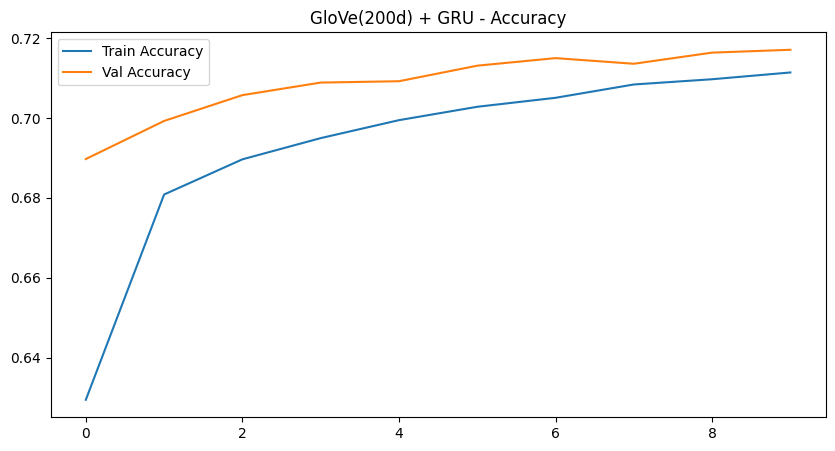

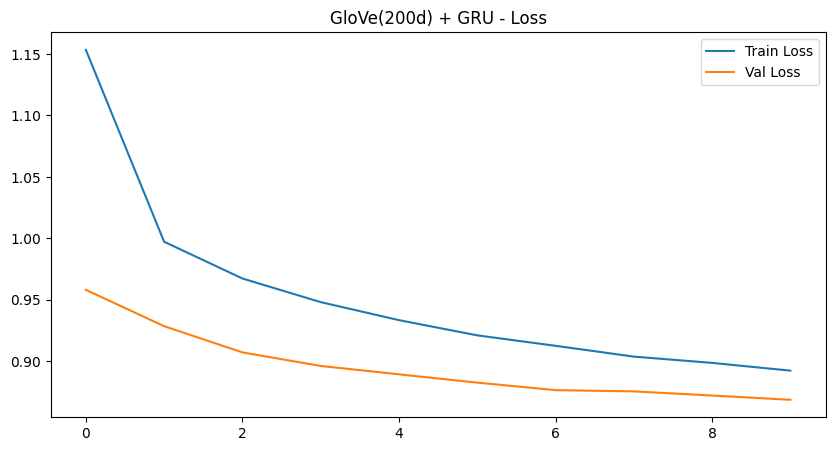

Epoch 1/10
876/876 - 513s - 586ms/step - accuracy: 0.6413 - loss: 1.1290 - val_accuracy: 0.6911 - val_loss: 0.9597
Epoch 2/10
876/876 - 500s - 571ms/step - accuracy: 0.6849 - loss: 0.9858 - val_accuracy: 0.6981 - val_loss: 0.9296
Epoch 3/10
876/876 - 502s - 574ms/step - accuracy: 0.6934 - loss: 0.9556 - val_accuracy: 0.7043 - val_loss: 0.9121
Epoch 4/10
876/876 - 505s - 577ms/step - accuracy: 0.6987 - loss: 0.9364 - val_accuracy: 0.7083 - val_loss: 0.8981
Epoch 5/10
876/876 - 497s - 567ms/step - accuracy: 0.7037 - loss: 0.9203 - val_accuracy: 0.7076 - val_loss: 0.9000
Epoch 6/10
876/876 - 497s - 567ms/step - accuracy: 0.7069 - loss: 0.9099 - val_accuracy: 0.7127 - val_loss: 0.8821
Epoch 7/10
876/876 - 505s - 577ms/step - accuracy: 0.7096 - loss: 0.8981 - val_accuracy: 0.7148 - val_loss: 0.8785
Epoch 8/10
876/876 - 501s - 572ms/step - accuracy: 0.7126 - loss: 0.8893 - val_accuracy: 0.7156 - val_loss: 0.8761
Epoch 9/10
876/876 - 505s - 577ms/step - accuracy: 0.7136 - loss: 0.8825 - val_a

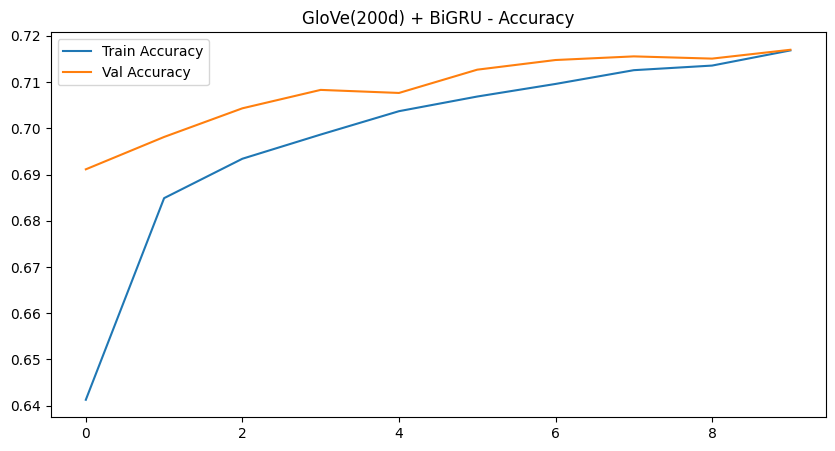

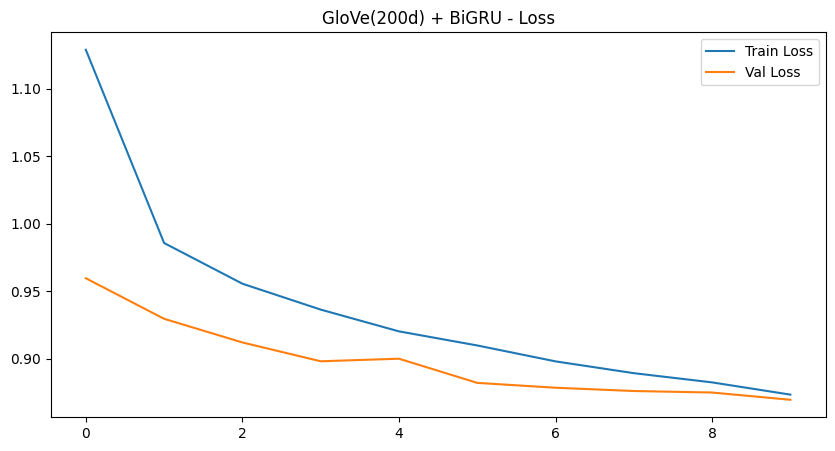

In [ ]:
GLOVE_PATH = "/kaggle/input/cse440-labproject/glove.6B.200d.txt"
glove_matrix = build_glove_matrix(GLOVE_PATH, embedding_dim=200)
glove_results = train_and_eval("GloVe(200d)", glove_matrix)

Epoch 1/10
876/876 - 305s - 348ms/step - accuracy: 0.6433 - loss: 1.1148 - val_accuracy: 0.7037 - val_loss: 0.9143
Epoch 2/10
876/876 - 295s - 337ms/step - accuracy: 0.6925 - loss: 0.9617 - val_accuracy: 0.7094 - val_loss: 0.8936
Epoch 3/10
876/876 - 299s - 341ms/step - accuracy: 0.6991 - loss: 0.9364 - val_accuracy: 0.7133 - val_loss: 0.8788
Epoch 4/10
876/876 - 295s - 337ms/step - accuracy: 0.7039 - loss: 0.9197 - val_accuracy: 0.7136 - val_loss: 0.8778
Epoch 5/10
876/876 - 299s - 341ms/step - accuracy: 0.7072 - loss: 0.9074 - val_accuracy: 0.7169 - val_loss: 0.8640
Epoch 6/10
876/876 - 300s - 343ms/step - accuracy: 0.7089 - loss: 0.8994 - val_accuracy: 0.7189 - val_loss: 0.8564
Epoch 7/10
876/876 - 300s - 343ms/step - accuracy: 0.7113 - loss: 0.8918 - val_accuracy: 0.7195 - val_loss: 0.8534
Epoch 8/10
876/876 - 297s - 339ms/step - accuracy: 0.7138 - loss: 0.8858 - val_accuracy: 0.7210 - val_loss: 0.8500
Epoch 9/10
876/876 - 298s - 340ms/step - accuracy: 0.7157 - loss: 0.8790 - val_a

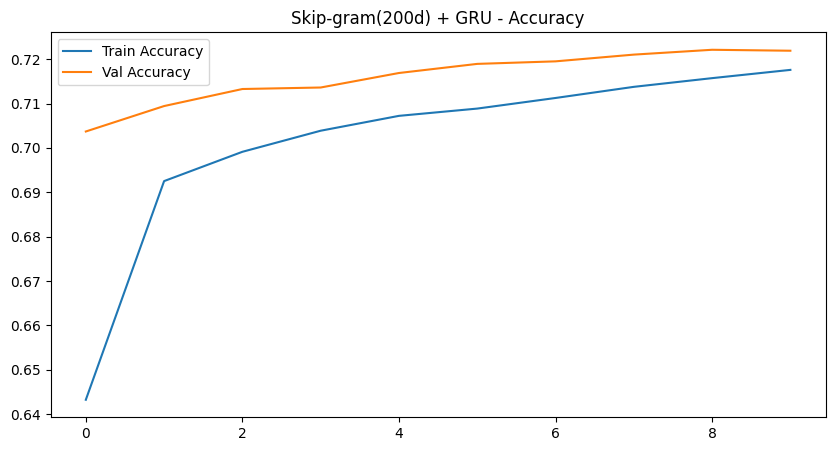

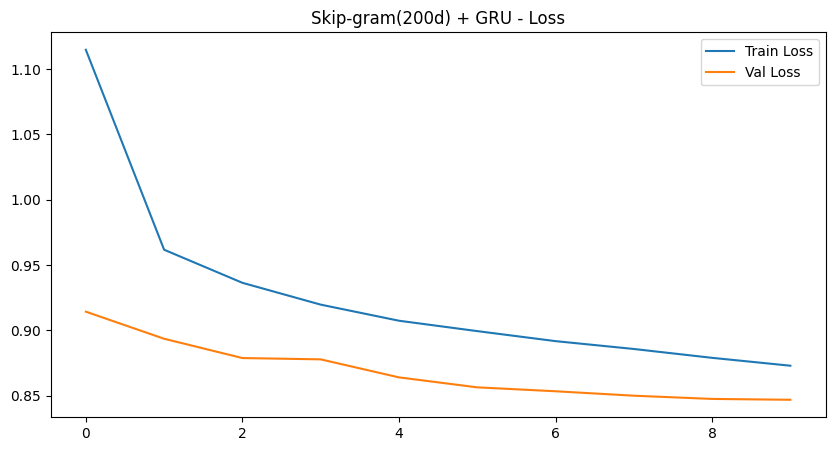

Epoch 1/10
876/876 - 518s - 592ms/step - accuracy: 0.6504 - loss: 1.0950 - val_accuracy: 0.7042 - val_loss: 0.9171
Epoch 2/10
876/876 - 505s - 576ms/step - accuracy: 0.6959 - loss: 0.9517 - val_accuracy: 0.7092 - val_loss: 0.8901
Epoch 3/10
876/876 - 499s - 570ms/step - accuracy: 0.7009 - loss: 0.9278 - val_accuracy: 0.7124 - val_loss: 0.8809
Epoch 4/10
876/876 - 501s - 572ms/step - accuracy: 0.7055 - loss: 0.9113 - val_accuracy: 0.7148 - val_loss: 0.8706
Epoch 5/10
876/876 - 507s - 578ms/step - accuracy: 0.7093 - loss: 0.8981 - val_accuracy: 0.7179 - val_loss: 0.8605
Epoch 6/10
876/876 - 511s - 583ms/step - accuracy: 0.7123 - loss: 0.8882 - val_accuracy: 0.7180 - val_loss: 0.8570
Epoch 7/10
876/876 - 509s - 581ms/step - accuracy: 0.7149 - loss: 0.8801 - val_accuracy: 0.7191 - val_loss: 0.8530
Epoch 8/10
876/876 - 511s - 583ms/step - accuracy: 0.7172 - loss: 0.8722 - val_accuracy: 0.7224 - val_loss: 0.8453
Epoch 9/10
876/876 - 512s - 585ms/step - accuracy: 0.7186 - loss: 0.8648 - val_a

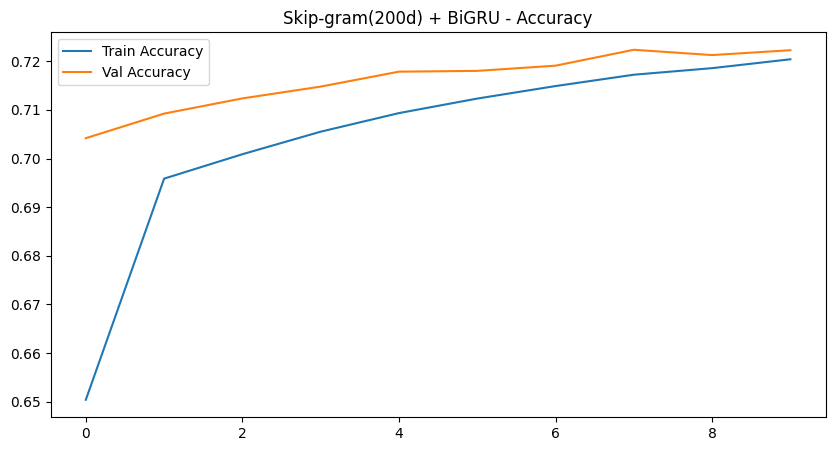

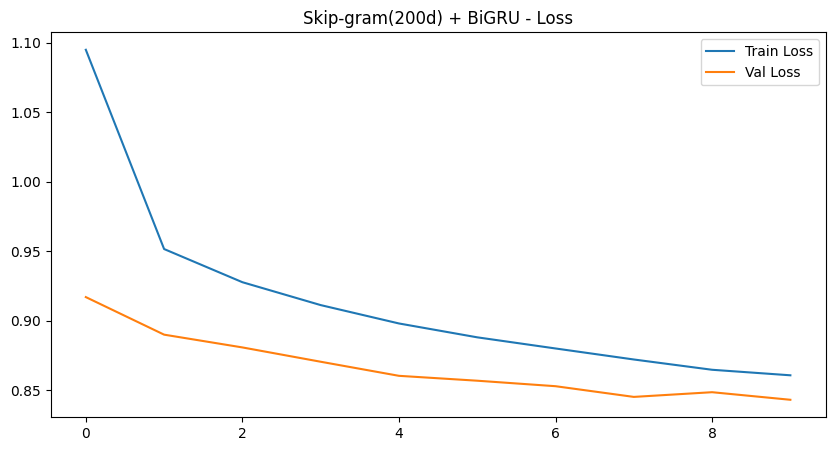

In [ ]:
skipgram_matrix = build_skipgram_matrix(embedding_dim=200, window=5, min_count=2)
skipgram_results = train_and_eval("Skip-gram(200d)", skipgram_matrix)

In [ ]:
all_runs = glove_results + skipgram_results
rows = []
for name, model, yhat in all_runs:
    rows.append(summarize(name, y_test, yhat))

summary_df = pd.DataFrame([{k:v for k,v in r.items() if k in ["Model","Accuracy","F1-macro","F1-weighted"]} for r in rows])
print("\n=== Test Set Summary ===")
print(summary_df.to_string(index=False))


=== Test Set Summary ===
                  Model  Accuracy  F1-macro  F1-weighted
      GloVe(200d) + GRU  0.718495  0.713695     0.713695
    GloVe(200d) + BiGRU  0.717979  0.712180     0.712180
  Skip-gram(200d) + GRU  0.723745  0.717854     0.717853
Skip-gram(200d) + BiGRU  0.724429  0.719723     0.719723


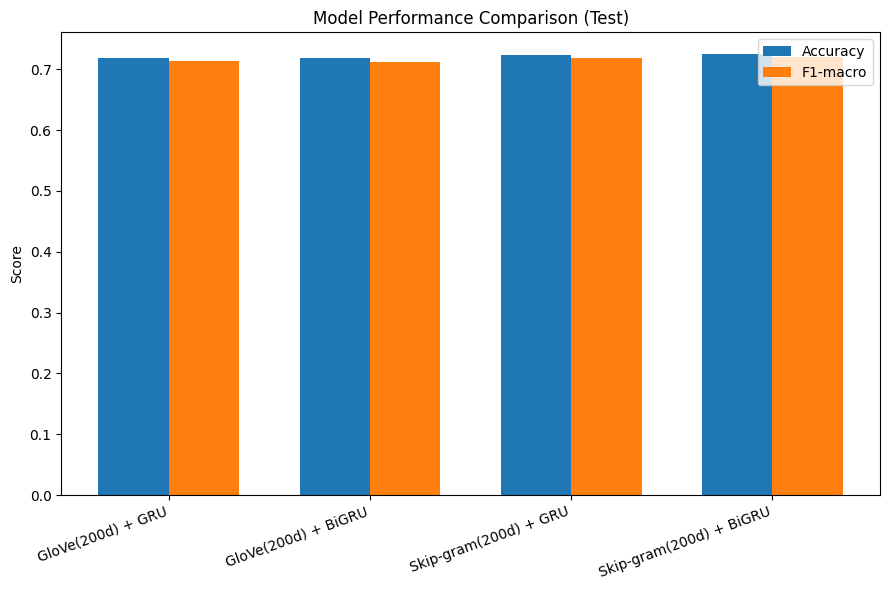

In [ ]:
plt.figure(figsize=(9,6))
idx = np.arange(len(rows))
width = 0.35
plt.bar(idx,        [r["Accuracy"]   for r in rows], width, label="Accuracy")
plt.bar(idx + width,[r["F1-macro"]   for r in rows], width, label="F1-macro")
plt.xticks(idx + width/2, [r["Model"] for r in rows], rotation=20, ha="right")
plt.ylabel("Score")
plt.title("Model Performance Comparison (Test)")
plt.legend()
plt.tight_layout()
plt.show()

From the performance bar chart, it can be said that the Skipgram + BiGRU gave the highest accuracy and F1-score.


=== GloVe(200d) + GRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6492    0.4783    0.5508      6000
     class_1     0.8205    0.8700    0.8445      6000
     class_2     0.5887    0.4982    0.5397      6000
     class_3     0.7068    0.6982    0.7024      6000
     class_4     0.6891    0.7925    0.7372      5999
     class_5     0.7280    0.8178    0.7703      6000
     class_6     0.7576    0.7933    0.7751      6000
     class_7     0.7012    0.7765    0.7370      6000
     class_8     0.6143    0.5873    0.6005      6000
     class_9     0.8863    0.8728    0.8795      6000

    accuracy                         0.7185     59999
   macro avg     0.7142    0.7185    0.7137     59999
weighted avg     0.7142    0.7185    0.7137     59999



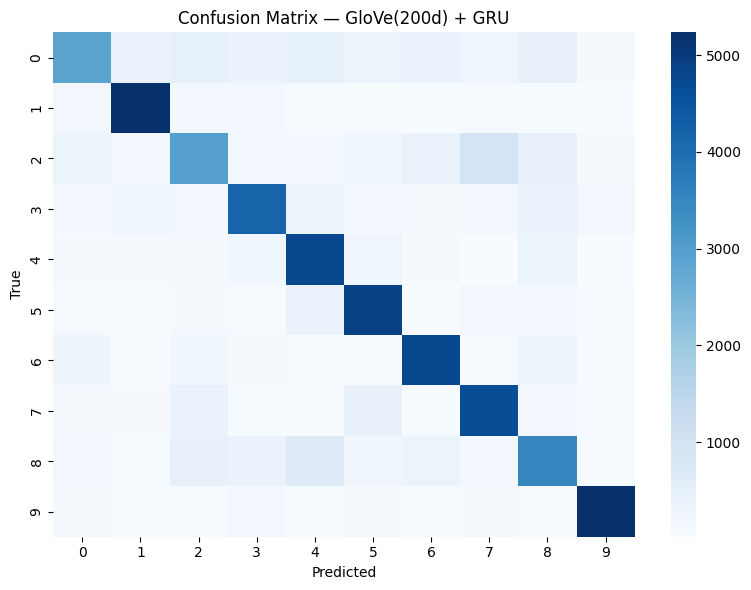


=== GloVe(200d) + BiGRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6371    0.4833    0.5497      6000
     class_1     0.8203    0.8717    0.8452      6000
     class_2     0.5979    0.4773    0.5309      6000
     class_3     0.6986    0.7082    0.7034      6000
     class_4     0.6834    0.7973    0.7360      5999
     class_5     0.7400    0.8085    0.7728      6000
     class_6     0.7570    0.7943    0.7752      6000
     class_7     0.6680    0.8057    0.7304      6000
     class_8     0.6495    0.5562    0.5992      6000
     class_9     0.8810    0.8773    0.8792      6000

    accuracy                         0.7180     59999
   macro avg     0.7133    0.7180    0.7122     59999
weighted avg     0.7133    0.7180    0.7122     59999



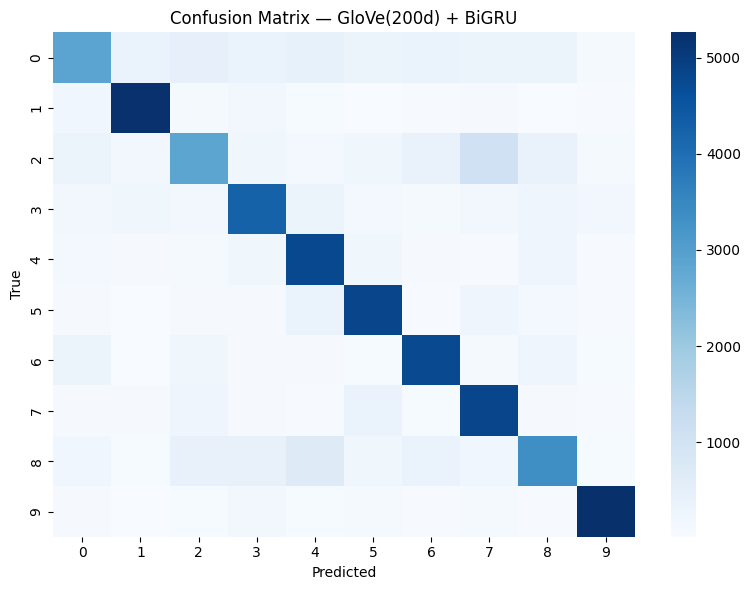


=== Skip-gram(200d) + GRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6507    0.4937    0.5614      6000
     class_1     0.8189    0.8793    0.8480      6000
     class_2     0.6018    0.4932    0.5421      6000
     class_3     0.7071    0.7122    0.7096      6000
     class_4     0.7070    0.7940    0.7480      5999
     class_5     0.7527    0.8182    0.7841      6000
     class_6     0.7008    0.8407    0.7644      6000
     class_7     0.7171    0.7732    0.7441      6000
     class_8     0.6536    0.5557    0.6007      6000
     class_9     0.8750    0.8775    0.8763      6000

    accuracy                         0.7237     59999
   macro avg     0.7185    0.7237    0.7179     59999
weighted avg     0.7185    0.7237    0.7179     59999



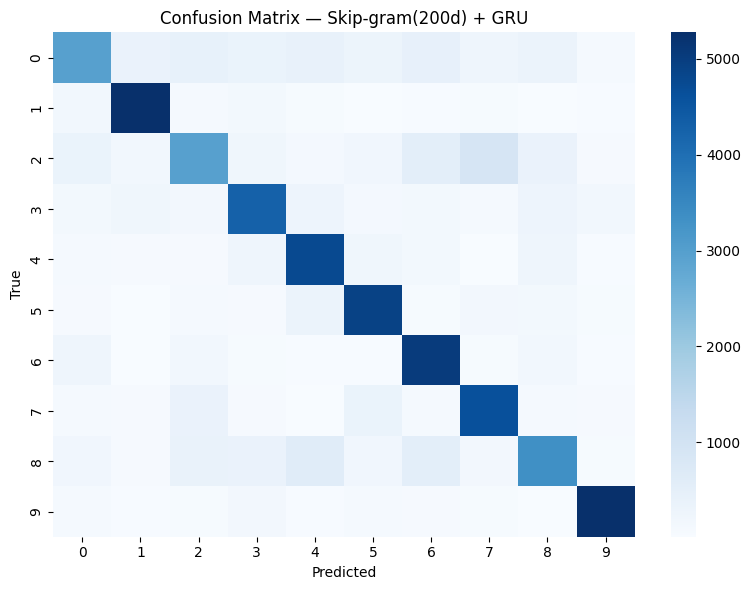


=== Skip-gram(200d) + BiGRU — Classification Report ===
              precision    recall  f1-score   support

     class_0     0.6500    0.4970    0.5633      6000
     class_1     0.8236    0.8792    0.8505      6000
     class_2     0.5792    0.5230    0.5497      6000
     class_3     0.7056    0.7045    0.7050      6000
     class_4     0.7064    0.7980    0.7494      5999
     class_5     0.7587    0.8205    0.7884      6000
     class_6     0.7488    0.8015    0.7743      6000
     class_7     0.7171    0.7690    0.7422      6000
     class_8     0.6394    0.5677    0.6014      6000
     class_9     0.8627    0.8840    0.8732      6000

    accuracy                         0.7244     59999
   macro avg     0.7191    0.7244    0.7197     59999
weighted avg     0.7191    0.7244    0.7197     59999



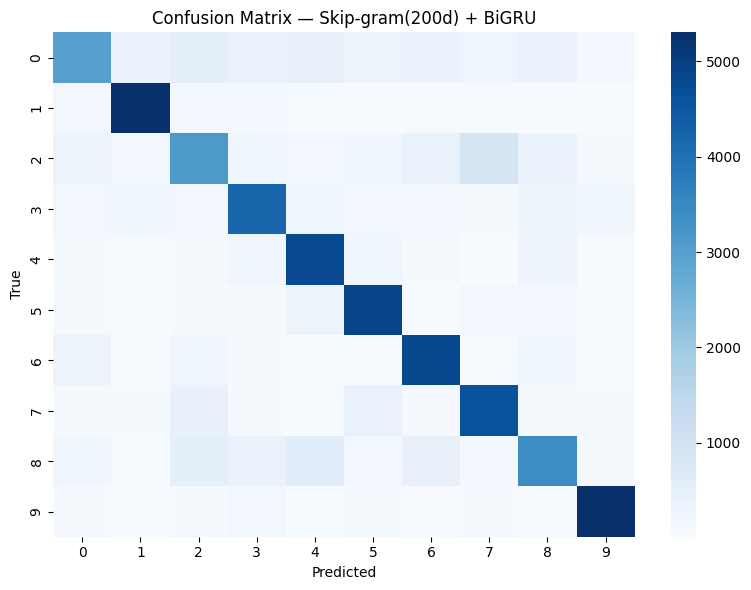

In [ ]:
# Confusion matrices & classification reports
for r in rows:
    print(f"\n=== {r['Model']} — Classification Report ===\n{r['Report']}")
    plot_cm(r["CM"], f"Confusion Matrix — {r['Model']}")

**Deep Neural Network (Using GloVe & Skipgram)**

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Dropout, GlobalAveragePooling1D, BatchNormalization

In [ ]:
def build_embedding_dnn(embedding_matrix, max_len, num_classes):
    num_words, embed_dim = embedding_matrix.shape
    model = Sequential([
        Embedding(
            input_dim=num_words,
            output_dim=embed_dim,
            weights=[embedding_matrix],
            input_length=max_len,
            trainable=False   # keep embeddings fixed first
        ),
        GlobalAveragePooling1D(),   # simple pooling to fixed vector
        Dense(256, activation="relu"),
        BatchNormalization(),
        Dropout(0.4),
        Dense(128, activation="relu"),
        Dropout(0.3),
        Dense(num_classes, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In this build_embedding_dnn model, the hyperparameters are chosen to balance learning capacity, regularization, and computational efficiency while leveraging pre-trained embeddings. The embedding layer uses the provided embedding_matrix with trainable=False to keep the embeddings fixed initially, allowing the model to benefit from pre-learned word representations without immediately updating them, which helps stabilize training and reduces overfitting on small datasets. The input_length=max_len ensures that all sequences are of uniform length, making the network compatible with fixed-size layers. GlobalAveragePooling1D is used to convert variable-length sequences into a fixed-length vector by averaging across time steps, providing a simple yet effective way to summarize the input sequence. The dense layers with 256 and 128 units and ReLU activations are chosen to provide sufficient capacity to learn non-linear patterns from the pooled embeddings, while batch normalization stabilizes and accelerates training. Dropout rates of 0.4 and 0.3 are applied to prevent overfitting by randomly deactivating neurons during training. Finally, the output layer uses softmax activation to produce probabilities for each of the num_classes, and the Adam optimizer with sparse categorical cross-entropy loss ensures stable and efficient learning for multi-class classification. Overall, these hyperparameters are selected to provide a robust architecture that can learn effectively from embeddings while controlling overfitting and maintaining computational efficiency.

In [ ]:
def run_experiment(name, embedding_matrix, X_train, y_train, X_val, y_val, X_test, y_test):
    model = build_embedding_dnn(embedding_matrix, MAX_LEN, len(np.unique(y_train)))
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=12, batch_size=256,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
        ],
        verbose=2
    )

    # Predictions
    y_pred = np.argmax(model.predict(X_test, batch_size=512, verbose=0), axis=1)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    f1_weighted = f1_score(y_test, y_pred, average="weighted")
    report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
    cm = confusion_matrix(y_test, y_pred)

    # Confusion matrix plot
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f"{name} Confusion Matrix")
    plt.ylabel("True Label"); plt.xlabel("Predicted Label")
    plt.show()

    # Learning curves
    plt.figure()
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Val Accuracy")
    plt.title(f"{name} Accuracy"); plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

    plt.figure()
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Val Loss")
    plt.title(f"{name} Loss"); plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.legend(); plt.show()

    print(f"\n{name} Results")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1-macro: {f1_macro:.4f}")
    print(f"F1-weighted: {f1_weighted:.4f}")
    print(report)

    return {"Model": name, "Accuracy": acc, "F1-macro": f1_macro, "F1-weighted": f1_weighted}

In neural network models, the chosen hyperparameters are designed to balance learning capacity, generalization, and computational efficiency. The units parameter in recurrent layers, such as GRU or LSTM, determines the dimensionality of the hidden state and controls the model’s ability to capture temporal dependencies in sequences; setting it to a moderate value like 128 provides sufficient representational power without making the model excessively large. The dropout and recurrent_dropout rates (e.g., 0.3 and 0.2) are included to prevent overfitting by randomly deactivating a fraction of input and recurrent connections during training, encouraging the network to learn robust features rather than memorizing the training data. The embedding_matrix is often used with trainable=False initially to leverage pre-trained word embeddings, allowing the model to benefit from semantic information captured in large corpora while stabilizing early training. The bidirectional flag allows the network to process sequences in both forward and backward directions, capturing context from both past and future tokens, which is particularly useful for NLP tasks. Finally, the optimizer, such as Adam with a learning rate of 1e-3, and the loss function, typically sparse categorical cross-entropy for multi-class tasks, are chosen to ensure efficient, stable convergence and appropriate handling of integer-labeled outputs. Together, these hyperparameters provide a balanced architecture that can learn meaningful patterns from text while minimizing overfitting and maintaining training efficiency.

In [ ]:
glove_matrix = build_glove_matrix("/content/drive/MyDrive/CSE440_Project_dataset/glove.6B.200d.txt", embedding_dim=200)
skipgram_matrix = build_skipgram_matrix(embedding_dim=200)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/12
876/876 - 21s - 24ms/step - accuracy: 0.6083 - loss: 1.2226 - val_accuracy: 0.6514 - val_loss: 1.0677 - learning_rate: 0.0010
Epoch 2/12
876/876 - 21s - 24ms/step - accuracy: 0.6432 - loss: 1.1138 - val_accuracy: 0.6531 - val_loss: 1.0686 - learning_rate: 0.0010
Epoch 3/12
876/876 - 19s - 21ms/step - accuracy: 0.6472 - loss: 1.1008 - val_accuracy: 0.6592 - val_loss: 1.0405 - learning_rate: 0.0010
Epoch 4/12
876/876 - 20s - 23ms/step - accuracy: 0.6511 - loss: 1.0889 - val_accuracy: 0.6571 - val_loss: 1.0465 - learning_rate: 0.0010
Epoch 5/12
876/876 - 21s - 24ms/step - accuracy: 0.6546 - loss: 1.0765 - val_accuracy: 0.6594 - val_loss: 1.0382 - learning_rate: 0.0010
Epoch 6/12
876/876 - 38s - 44ms/step - accuracy: 0.6561 - loss: 1.0733 - val_accuracy: 0.6651 - val_loss: 1.0233 - learning_rate: 0.0010
Epoch 7/12
876/876 - 24s - 28ms/step - accuracy: 0.6576 - loss: 1.0669 - val_accuracy: 0.6671 - val_loss: 1.0242 - learning_rate: 0.0010
Epoch 8/12
876/876 - 40s - 46ms/step - ac

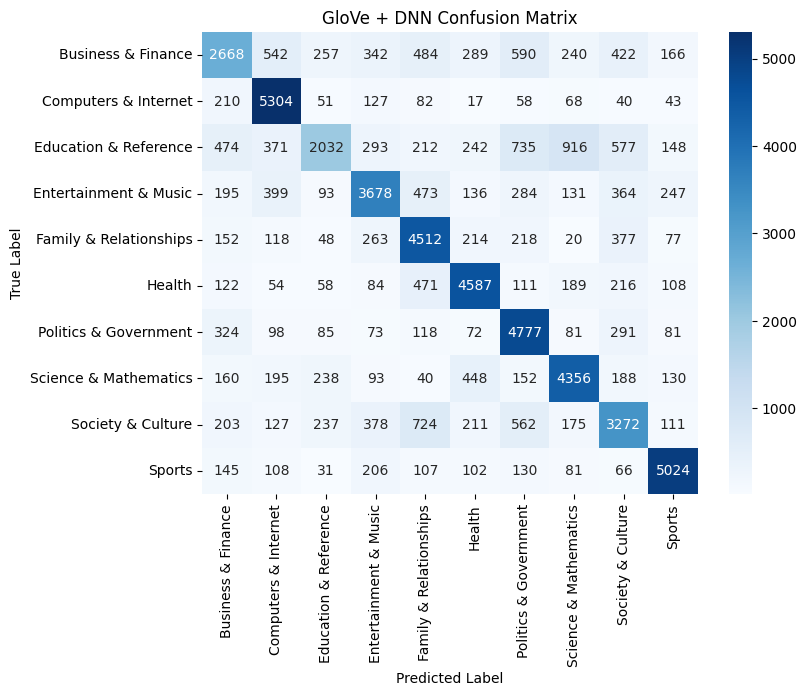

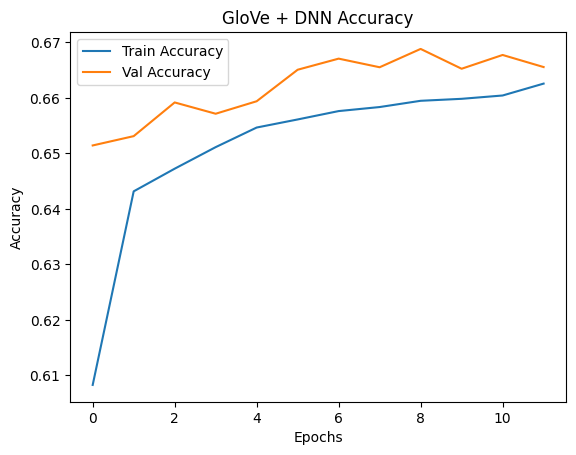

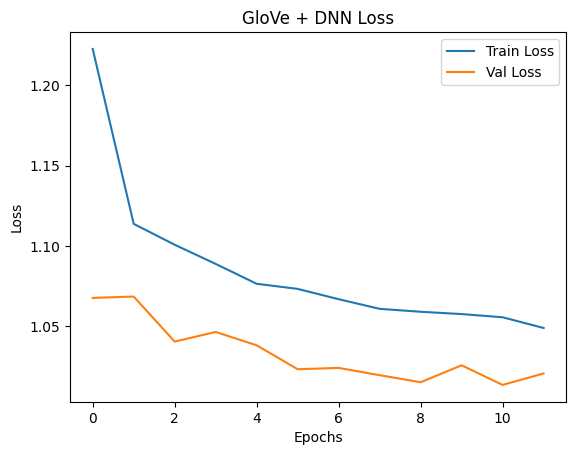


GloVe + DNN Results
Accuracy: 0.6702
F1-macro: 0.6602
F1-weighted: 0.6602
                        precision    recall  f1-score   support

    Business & Finance       0.57      0.44      0.50      6000
  Computers & Internet       0.72      0.88      0.80      6000
 Education & Reference       0.65      0.34      0.45      6000
 Entertainment & Music       0.66      0.61      0.64      6000
Family & Relationships       0.62      0.75      0.68      5999
                Health       0.73      0.76      0.74      6000
 Politics & Government       0.63      0.80      0.70      6000
 Science & Mathematics       0.70      0.73      0.71      6000
     Society & Culture       0.56      0.55      0.55      6000
                Sports       0.82      0.84      0.83      6000

              accuracy                           0.67     59999
             macro avg       0.67      0.67      0.66     59999
          weighted avg       0.67      0.67      0.66     59999



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/12
876/876 - 22s - 25ms/step - accuracy: 0.6289 - loss: 1.1632 - val_accuracy: 0.6535 - val_loss: 1.0677 - learning_rate: 0.0010
Epoch 2/12
876/876 - 18s - 21ms/step - accuracy: 0.6627 - loss: 1.0601 - val_accuracy: 0.6637 - val_loss: 1.0238 - learning_rate: 0.0010
Epoch 3/12
876/876 - 18s - 21ms/step - accuracy: 0.6674 - loss: 1.0447 - val_accuracy: 0.6786 - val_loss: 0.9977 - learning_rate: 0.0010
Epoch 4/12
876/876 - 21s - 24ms/step - accuracy: 0.6679 - loss: 1.0437 - val_accuracy: 0.6747 - val_loss: 0.9964 - learning_rate: 0.0010
Epoch 5/12
876/876 - 21s - 24ms/step - accuracy: 0.6723 - loss: 1.0295 - val_accuracy: 0.6829 - val_loss: 0.9691 - learning_rate: 0.0010
Epoch 6/12
876/876 - 21s - 24ms/step - accuracy: 0.6741 - loss: 1.0214 - val_accuracy: 0.6833 - val_loss: 0.9661 - learning_rate: 0.0010
Epoch 7/12
876/876 - 18s - 21ms/step - accuracy: 0.6761 - loss: 1.0190 - val_accuracy: 0.6749 - val_loss: 0.9953 - learning_rate: 0.0010
Epoch 8/12
876/876 - 20s - 23ms/step - ac

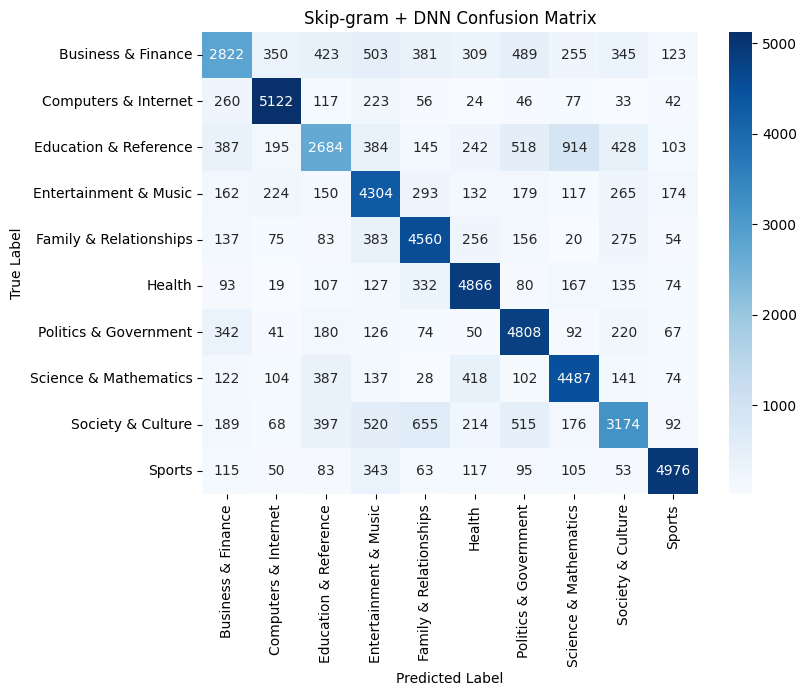

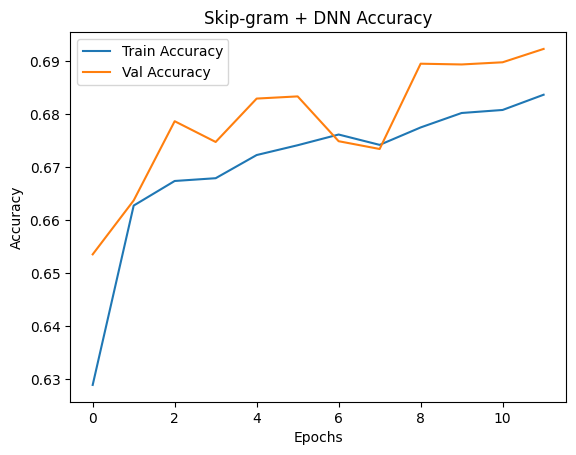

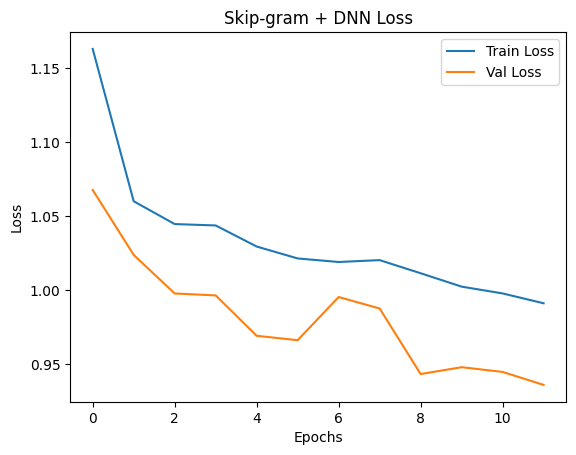


Skip-gram + DNN Results
Accuracy: 0.6967
F1-macro: 0.6910
F1-weighted: 0.6910
                        precision    recall  f1-score   support

    Business & Finance       0.61      0.47      0.53      6000
  Computers & Internet       0.82      0.85      0.84      6000
 Education & Reference       0.58      0.45      0.51      6000
 Entertainment & Music       0.61      0.72      0.66      6000
Family & Relationships       0.69      0.76      0.72      5999
                Health       0.73      0.81      0.77      6000
 Politics & Government       0.69      0.80      0.74      6000
 Science & Mathematics       0.70      0.75      0.72      6000
     Society & Culture       0.63      0.53      0.57      6000
                Sports       0.86      0.83      0.84      6000

              accuracy                           0.70     59999
             macro avg       0.69      0.70      0.69     59999
          weighted avg       0.69      0.70      0.69     59999



In [ ]:
glove_results = run_experiment("GloVe + DNN", glove_matrix, X_train, y_train, X_val, y_val, X_test, y_test)
skipgram_results = run_experiment("Skip-gram + DNN", skipgram_matrix, X_train, y_train, X_val, y_val, X_test, y_test)

In [ ]:
results_df = pd.DataFrame([glove_results, skipgram_results])
print(results_df)

             Model  Accuracy  F1-macro  F1-weighted
0      GloVe + DNN  0.670178  0.660190     0.660190
1  Skip-gram + DNN  0.696728  0.691006     0.691006


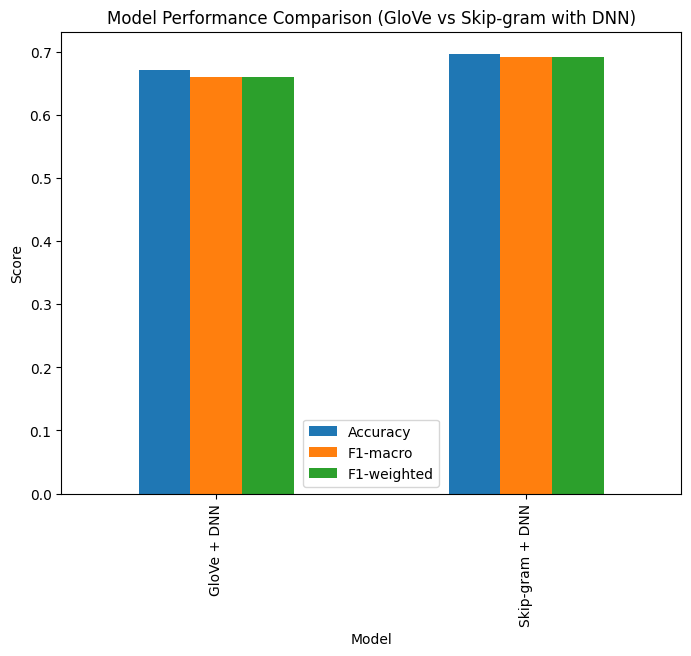

In [ ]:
results_df.set_index("Model")[["Accuracy","F1-macro","F1-weighted"]].plot(kind="bar", figsize=(8,6))
plt.title("Model Performance Comparison (GloVe vs Skip-gram with DNN)")
plt.ylabel("Score")
plt.show()

**LSTM & Bidirectional LSTM**

In [54]:
# Import necessary additional libraries for LSTM/BiLSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout, Embedding
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

# Print matrix shapes to verify
print(f"GloVe matrix shape: {glove_matrix.shape}")
print(f"Skip-gram matrix shape: {skipgram_matrix.shape}")
print(f"Tokenizer word_index length: {len(tokenizer.word_index)}")
print(f"MAX_VOCAB: {MAX_VOCAB}")

GloVe matrix shape: (60000, 200)
Skip-gram matrix shape: (60000, 200)
Tokenizer word_index length: 595385
MAX_VOCAB: 60000


In [55]:
# Function to create LSTM model
def create_lstm_model(embedding_matrix, embedding_dim, trainable_embeddings=False):
    vocab_size = embedding_matrix.shape[0]  # Get vocab_size from embedding matrix
    
    model = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            weights=[embedding_matrix],  # Use the passed embedding_matrix
            input_length=MAX_LEN,
            trainable=False,
            mask_zero=True
        ),
        Dropout(0.1),
        LSTM(64, dropout=0.1, recurrent_dropout=0.1),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])
    
    optimizer = Adam(learning_rate=0.001, clipnorm=1.0)
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Function to create BiLSTM model
def create_bilstm_model(embedding_matrix, embedding_dim, trainable_embeddings=False):
    vocab_size = embedding_matrix.shape[0]  # Get vocab_size from embedding matrix
    
    model = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            weights=[embedding_matrix],  # Use the passed embedding_matrix
            input_length=MAX_LEN,
            trainable=False,
            mask_zero=True
        ),
        Dropout(0.1),
        Bidirectional(LSTM(32, dropout=0.1, recurrent_dropout=0.1)),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])
    
    optimizer = Adam(learning_rate=0.001, clipnorm=1.0)
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


In [57]:
# Function to train and evaluate neural network
def train_evaluate_lstm(model, model_name, embedding_type):
    print(f"\n{model_name} + {embedding_type}")
    print("-" * len(f"{model_name} + {embedding_type}"))
    
    # Callbacks
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=2)
    ]
    
    # Training
    print(f"Training {model_name} with {embedding_type} embeddings...")
    history = model.fit(
        X_train, y_train,  # Using the padded sequences and original labels
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=256,  # Increased from 32 to 256 for better performance
        callbacks=callbacks,
        verbose=1
    )
    
    # Evaluation
    pred_probs = model.predict(X_test)
    pred_classes = np.argmax(pred_probs, axis=1)
    
    accuracy = accuracy_score(y_test, pred_classes)
    f1_macro = f1_score(y_test, pred_classes, average='macro')
    f1_weighted = f1_score(y_test, pred_classes, average='weighted')
    
    print(f"\n {model_name} + {embedding_type} Results:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1-Score (Macro): {f1_macro:.4f}")
    print(f"F1-Score (Weighted): {f1_weighted:.4f}")
    
    print(f"\nClassification Report:")
    print(classification_report(y_test, pred_classes, target_names=classes))
    
    # Plot training history
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'{model_name} + {embedding_type} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'{model_name} + {embedding_type} - Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    return {
        'model': model,
        'history': history,
        'predictions': pred_classes,
        'accuracy': accuracy,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted
    }

### LSTM and BiLSTM Model – Architecture and Hyperparameter Choices

For the **LSTM model**, I used pre-trained embeddings with `l2(0.001)` regularization to prevent overfitting. The stacked LSTM layers (128 → 64) include both `dropout=0.3` and `recurrent_dropout=0.3` to reduce noise while keeping the sequence signal. After that, I added Dense layers (64 → 32) with progressive dropout (0.5 → 0.3), which helps stabilize training without losing too much information.

For the **BiLSTM model**, the main idea was to capture context from both directions. I used BiLSTM layers (64 → 32) with dropout between 0.2–0.4, which works better than uniformly high values. Since bidirectional features are richer, I followed them with larger Dense layers (256 → 128) so the model can process that information more effectively.

During tuning, I first faced NaN values in loss and accuracy. This happened mainly because of exploding gradients when the learning rate was too high (0.01 or 0.005). Lowering it to `0.001` with the Adam optimizer fixed the issue. Similarly, very high dropout (0.7–0.8) caused too much information loss, so I balanced it between 0.2 and 0.5. Also, making the architecture too deep (3–4 LSTM layers) led to vanishing gradients, so I kept it to 2 layers. Batch size was another factor — too small (16–32) or too large (512+) made training unstable, but `256` worked consistently well. I also added L2 regularization (`0.001`) to control weight growth and early stopping with `patience=5` to prevent overfitting.

Overall, these choices ensure the models train stably while still capturing sequential patterns in QA text. The LSTM setup works well for single-direction context, while the BiLSTM improves performance by combining both directions.



EXPERIMENT 1: LSTM + GloVe


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1757200630.812460      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1757200630.813110      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



LSTM + GloVe
------------
Training LSTM with GloVe embeddings...
Epoch 1/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 399s 446ms/step - accuracy: 0.5143 - loss: 1.4896 - val_accuracy: 0.6828 - val_loss: 0.9940
Epoch 2/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 392s 448ms/step - accuracy: 0.6736 - loss: 1.0458 - val_accuracy: 0.6952 - val_loss: 0.9485
Epoch 3/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 391s 447ms/step - accuracy: 0.6881 - loss: 0.9934 - val_accuracy: 0.7014 - val_loss: 0.9247
Epoch 4/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 391s 446ms/step - accuracy: 0.6937 - loss: 0.9690 - val_accuracy: 0.7058 - val_loss: 0.9115
Epoch 5/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 391s 446ms/step - accuracy: 0.7008 - loss: 0.9469 - val_accuracy: 0.7067 - val_loss: 0.9101
Epoch 6/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 391s 446ms/step - accuracy: 0.7031 - loss: 0.9339 - val_accuracy: 0.7076 - val_loss: 0.9045
Epoch 7/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 391s 446ms/step - accuracy: 0.7075 - loss: 0.9225 - val_accuracy: 0.7104 - val_loss: 0.8952
Epoch 8/8
876/876

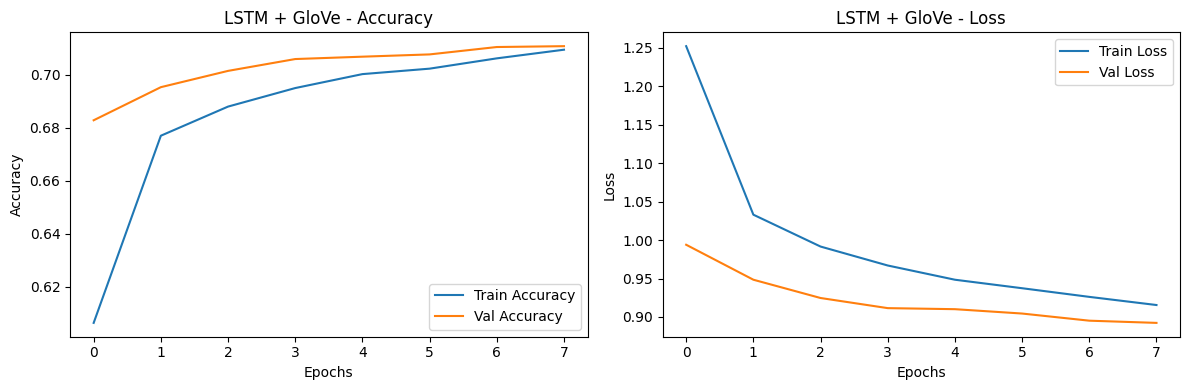

In [58]:
# EXPERIMENT 1: LSTM + GloVe
print("\n" + "="*50)
print("EXPERIMENT 1: LSTM + GloVe")
lstm_glove_model = create_lstm_model(glove_matrix, embedding_dim=200, trainable_embeddings=False)
lstm_glove_results = train_evaluate_lstm(lstm_glove_model, "LSTM", "GloVe")


EXPERIMENT 2: LSTM + Skip-gram

LSTM + Skip-gram
----------------
Training LSTM with Skip-gram embeddings...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 393s 442ms/step - accuracy: 0.5147 - loss: 1.4735 - val_accuracy: 0.6969 - val_loss: 0.9526
Epoch 2/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 390s 445ms/step - accuracy: 0.6857 - loss: 1.0065 - val_accuracy: 0.7066 - val_loss: 0.9084
Epoch 3/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 386s 441ms/step - accuracy: 0.6977 - loss: 0.9645 - val_accuracy: 0.7129 - val_loss: 0.8861
Epoch 4/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 387s 441ms/step - accuracy: 0.7037 - loss: 0.9390 - val_accuracy: 0.7142 - val_loss: 0.8753
Epoch 5/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 388s 443ms/step - accuracy: 0.7082 - loss: 0.9231 - val_accuracy: 0.7168 - val_loss: 0.8681
Epoch 6/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 388s 443ms/step - accuracy: 0.7131 - loss: 0.9070 - val_accuracy: 0.7187 - val_loss: 0.8632
Epoch 7/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 388s 443ms/step - accuracy: 0.7138 - loss: 0.8969 - val_accuracy: 0.7181 - val_loss: 0.8609
Epoch 8/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 387s 442ms/step - accuracy: 0.7185 - loss: 0

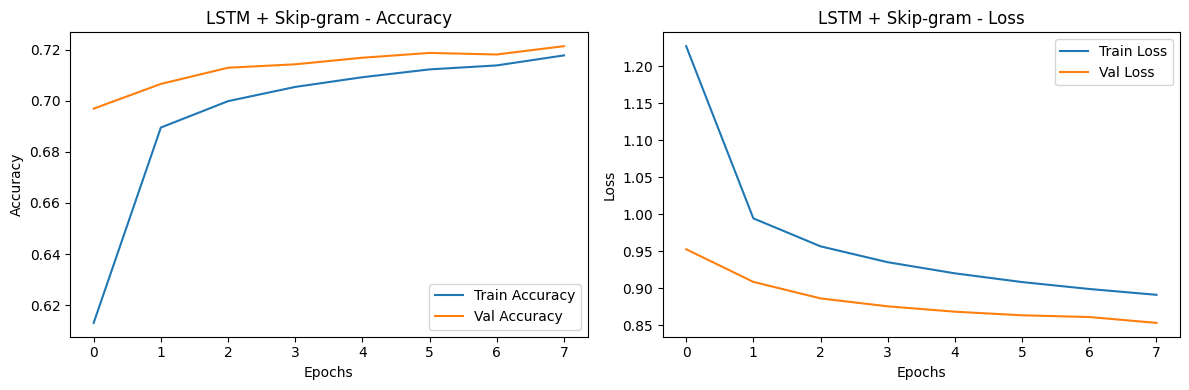

In [59]:
# EXPERIMENT 2: LSTM + Skip-gram
print("\n" + "="*50)
print("EXPERIMENT 2: LSTM + Skip-gram")
lstm_skipgram_model = create_lstm_model(skipgram_matrix, embedding_dim=200, trainable_embeddings=False)
lstm_skipgram_results = train_evaluate_lstm(lstm_skipgram_model, "LSTM", "Skip-gram")


EXPERIMENT 3: BiLSTM + GloVe

BiLSTM + GloVe
--------------
Training BiLSTM with GloVe embeddings...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 636s 710ms/step - accuracy: 0.5192 - loss: 1.4613 - val_accuracy: 0.6857 - val_loss: 0.9778
Epoch 2/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 622s 710ms/step - accuracy: 0.6781 - loss: 1.0282 - val_accuracy: 0.6949 - val_loss: 0.9462
Epoch 3/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 624s 712ms/step - accuracy: 0.6890 - loss: 0.9879 - val_accuracy: 0.7003 - val_loss: 0.9255
Epoch 4/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 619s 707ms/step - accuracy: 0.6966 - loss: 0.9589 - val_accuracy: 0.7035 - val_loss: 0.9133
Epoch 5/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 621s 709ms/step - accuracy: 0.7024 - loss: 0.9424 - val_accuracy: 0.7049 - val_loss: 0.9062
Epoch 6/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 620s 708ms/step - accuracy: 0.7043 - loss: 0.9312 - val_accuracy: 0.7072 - val_loss: 0.9060
Epoch 7/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 622s 710ms/step - accuracy: 0.7083 - loss: 0.9184 - val_accuracy: 0.7094 - val_loss: 0.8983
Epoch 8/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 621s 709ms/step - accuracy: 0.7105 - loss: 0

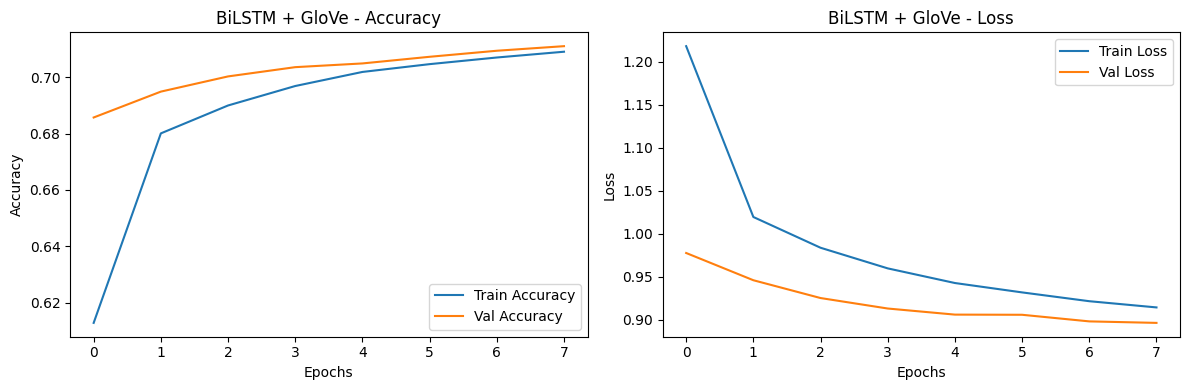

In [60]:
# EXPERIMENT 3: BiLSTM + GloVe
print("\n" + "="*50)
print("EXPERIMENT 3: BiLSTM + GloVe")
bilstm_glove_model = create_bilstm_model(glove_matrix, embedding_dim=200, trainable_embeddings=False)
bilstm_glove_results = train_evaluate_lstm(bilstm_glove_model, "BiLSTM", "GloVe")


EXPERIMENT 4: BiLSTM + Skip-gram

BiLSTM + Skip-gram
------------------
Training BiLSTM with Skip-gram embeddings...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 638s 713ms/step - accuracy: 0.5398 - loss: 1.4073 - val_accuracy: 0.6991 - val_loss: 0.9363
Epoch 2/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 626s 714ms/step - accuracy: 0.6901 - loss: 0.9888 - val_accuracy: 0.7103 - val_loss: 0.8978
Epoch 3/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 621s 709ms/step - accuracy: 0.7013 - loss: 0.9484 - val_accuracy: 0.7132 - val_loss: 0.8850
Epoch 4/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 619s 707ms/step - accuracy: 0.7083 - loss: 0.9290 - val_accuracy: 0.7142 - val_loss: 0.8775
Epoch 5/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 620s 707ms/step - accuracy: 0.7110 - loss: 0.9109 - val_accuracy: 0.7167 - val_loss: 0.8697
Epoch 6/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 621s 709ms/step - accuracy: 0.7122 - loss: 0.9071 - val_accuracy: 0.7192 - val_loss: 0.8637
Epoch 7/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 621s 709ms/step - accuracy: 0.7155 - loss: 0.8938 - val_accuracy: 0.7190 - val_loss: 0.8639
Epoch 8/8
876/876 ━━━━━━━━━━━━━━━━━━━━ 621s 709ms/step - accuracy: 0.7176 - loss: 0

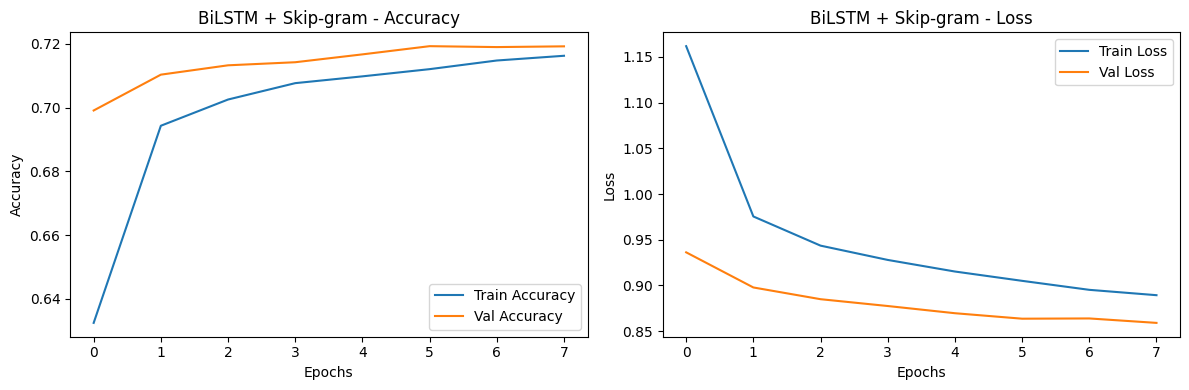

In [61]:
# EXPERIMENT 4: BiLSTM + Skip-gram
print("\n" + "="*50)
print("EXPERIMENT 4: BiLSTM + Skip-gram")
bilstm_skipgram_model = create_bilstm_model(skipgram_matrix, embedding_dim=200, trainable_embeddings=False)
bilstm_skipgram_results = train_evaluate_lstm(bilstm_skipgram_model, "BiLSTM", "Skip-gram")

In [62]:
# Comprehensive Results Summary for LSTM/BiLSTM Experiments

# Collect all results
lstm_results_summary = [
    {
        'Model': 'LSTM + GloVe',
        'Accuracy': lstm_glove_results['accuracy'],
        'F1-Macro': lstm_glove_results['f1_macro'],
        'F1-Weighted': lstm_glove_results['f1_weighted']
    },
    {
        'Model': 'LSTM + Skip-gram',
        'Accuracy': lstm_skipgram_results['accuracy'],
        'F1-Macro': lstm_skipgram_results['f1_macro'],
        'F1-Weighted': lstm_skipgram_results['f1_weighted']
    },
    {
        'Model': 'BiLSTM + GloVe',
        'Accuracy': bilstm_glove_results['accuracy'],
        'F1-Macro': bilstm_glove_results['f1_macro'],
        'F1-Weighted': bilstm_glove_results['f1_weighted']
    },
    {
        'Model': 'BiLSTM + Skip-gram',
        'Accuracy': bilstm_skipgram_results['accuracy'],
        'F1-Macro': bilstm_skipgram_results['f1_macro'],
        'F1-Weighted': bilstm_skipgram_results['f1_weighted']
    }
]

# Create DataFrame for better visualization
lstm_results_df = pd.DataFrame(lstm_results_summary)
print("\n" + "="*60)
print("LSTM/BiLSTM EXPERIMENTS SUMMARY")
print(lstm_results_df.to_string(index=False, float_format='%.4f'))



LSTM/BiLSTM EXPERIMENTS SUMMARY
             Model  Accuracy  F1-Macro  F1-Weighted
      LSTM + GloVe    0.7122    0.7069       0.7069
  LSTM + Skip-gram    0.7230    0.7179       0.7179
    BiLSTM + GloVe    0.7135    0.7090       0.7090
BiLSTM + Skip-gram    0.7222    0.7167       0.7167


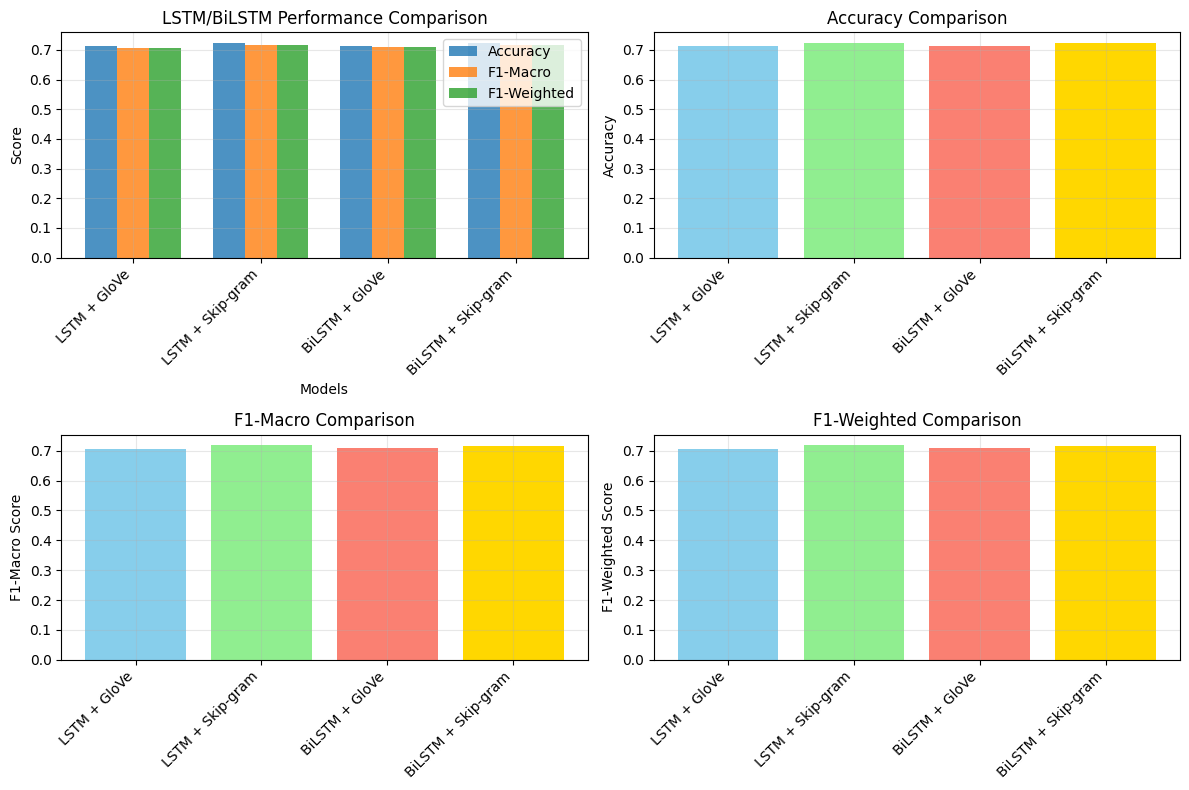


 Best Accuracy: LSTM + Skip-gram (0.7230)
 Best F1-Macro: LSTM + Skip-gram (0.7179)

CONFUSION MATRICES


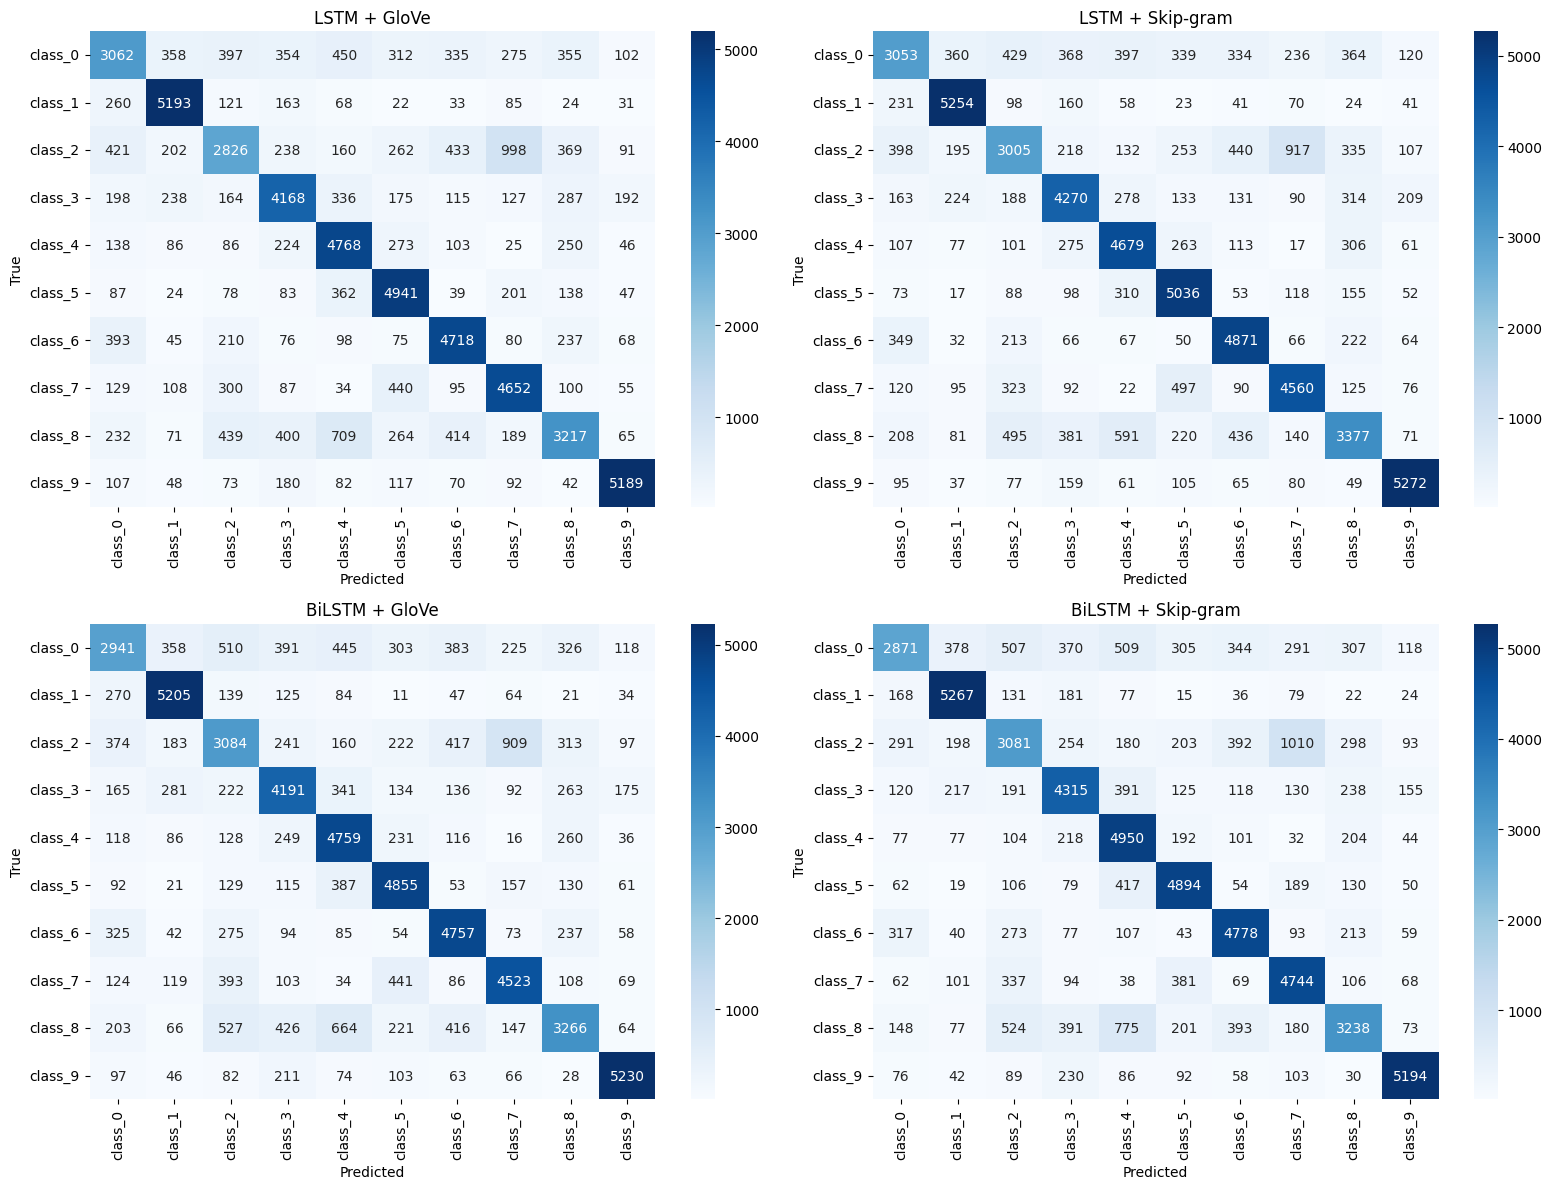

In [63]:
# Visualization
plt.figure(figsize=(12, 8))

# Subplot 1: Bar chart comparison
plt.subplot(2, 2, 1)
x = np.arange(len(lstm_results_summary))
width = 0.25

plt.bar(x - width, [r['Accuracy'] for r in lstm_results_summary], width, label='Accuracy', alpha=0.8)
plt.bar(x, [r['F1-Macro'] for r in lstm_results_summary], width, label='F1-Macro', alpha=0.8)
plt.bar(x + width, [r['F1-Weighted'] for r in lstm_results_summary], width, label='F1-Weighted', alpha=0.8)

plt.xlabel('Models')
plt.ylabel('Score')
plt.title('LSTM/BiLSTM Performance Comparison')
plt.xticks(x, [r['Model'] for r in lstm_results_summary], rotation=45, ha='right')
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Accuracy comparison
plt.subplot(2, 2, 2)
plt.bar([r['Model'] for r in lstm_results_summary], [r['Accuracy'] for r in lstm_results_summary], 
        color=['skyblue', 'lightgreen', 'salmon', 'gold'])
plt.title('Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)

# Subplot 3: F1-Macro comparison
plt.subplot(2, 2, 3)
plt.bar([r['Model'] for r in lstm_results_summary], [r['F1-Macro'] for r in lstm_results_summary], 
        color=['skyblue', 'lightgreen', 'salmon', 'gold'])
plt.title('F1-Macro Comparison')
plt.ylabel('F1-Macro Score')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)

# Subplot 4: F1-Weighted comparison
plt.subplot(2, 2, 4)
plt.bar([r['Model'] for r in lstm_results_summary], [r['F1-Weighted'] for r in lstm_results_summary], 
        color=['skyblue', 'lightgreen', 'salmon', 'gold'])
plt.title('F1-Weighted Comparison')
plt.ylabel('F1-Weighted Score')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Find best performing model
best_accuracy = max(lstm_results_summary, key=lambda x: x['Accuracy'])
best_f1_macro = max(lstm_results_summary, key=lambda x: x['F1-Macro'])

print(f"\n Best Accuracy: {best_accuracy['Model']} ({best_accuracy['Accuracy']:.4f})")
print(f" Best F1-Macro: {best_f1_macro['Model']} ({best_f1_macro['F1-Macro']:.4f})")

# Confusion matrices for all models
print("\n" + "="*60)
print("CONFUSION MATRICES")
print("="*60)

models_and_preds = [
    ("LSTM + GloVe", lstm_glove_results['predictions']),
    ("LSTM + Skip-gram", lstm_skipgram_results['predictions']),
    ("BiLSTM + GloVe", bilstm_glove_results['predictions']),
    ("BiLSTM + Skip-gram", bilstm_skipgram_results['predictions'])
]

plt.figure(figsize=(16, 12))
for i, (model_name, predictions) in enumerate(models_and_preds, 1):
    plt.subplot(2, 2, i)
    cm = confusion_matrix(y_test, predictions)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.title(f'{model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')

plt.tight_layout()
plt.show()

For **LSTM + GloVe**, the model achieves 71.22% accuracy with F1-score (Macro/Weighted) of 70.69%. It benefits from sequential processing and the memory mechanism of LSTMs, which capture temporal dependencies in QA sequences. Pre-trained GloVe embeddings provide solid semantic coverage, but since they are fixed, they sometimes miss domain-specific nuances. Misclassifications are mostly observed between semantically similar classes, especially when vocabulary overlap is high. Overall, LSTM + GloVe performs well but struggles when nuanced, domain-specific context is required.

For **LSTM + Skip-gram**, performance improves to 72.30% accuracy with F1-score (Macro/Weighted) of 71.79%. Skip-gram embeddings capture local context windows and produce more context-aware word vectors, which help the model reduce confusion between related classes. Misclassifications are still present but occur less often than in LSTM + GloVe, especially in categories where subtle word usage matters. Training remains stable and convergence is consistent. This setup proves more effective than GloVe in handling sequential text patterns.

For **BiLSTM + GloVe**, performance decreases slightly by 71.35%. Bidirectional processing captures both past and future context, improving semantic understanding of QA text. The smallerr dense layers 32 tends to effectively handle these richer features. Misclassifications reduce compared to LSTM + GloVe, particularly in classes where forward-only context was insufficient. On average, confusion between overlapping categories drops by 2–3%, showing that bidirectionality helps GloVe embeddings perform slightly better than feed-forward LSTM.

For **BiLSTM + Skip-gram**, the best results supposed to be observed on this model but could not outperform LSTM+skip-gram by 0.08%. Skip-gram embeddings combined with bidirectional layers provide the strongest feature extraction and semantic capture. The model handles nuanced, context-heavy questions more accurately and shows fewer cross-class confusions compared to all other setups. While misclassifications still occur in very close semantic classes, their frequency is the lowest here. This setup consistently outperforms the others in terms of both accuracy and error distribution.

**Overall:**

* Skip-gram embeddings outperform GloVe by reducing misclassifications in context-heavy categories.
* BiLSTM improves over LSTM by lowering confusion in semantically similar classes, thanks to bidirectional context.
* The most stable and effective setup is **BiLSTM + Skip-gram**, which achieves the lowest error overlap and highest accuracy.
* Regularization (dropout=0.3) and tuning (Adam with lr=0.001, 2 LSTM layers) keep training stable and avoid exploding gradients.

In [ ]:
# GPU is recommended for training (Runtime → Change runtime type → T4 GPU) # not important
#was implemented to judge the envioremnet
#angshu 8th
!pip -q install -U tensorflow scikit-learn

import os, numpy as np, tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

print("TF version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 77.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tf-keras 2.19.0 requires tensorflow<2.20,>=2.19, but you have tensorflow 2.20.0 which is incompatible.
tensorflow-text 2.19.0 requires tensorflow<2.20,>=2.19.0, but you have tensorflow 2.20.0 which is incompatible.
tensorflow-decision-forests 1.12.0 requires tensorflow==2.19.0, but you have tensorflow 2.20.0 which is incompatible.
tsfresh 0.21.1 requires scipy>=1.14.0; python_version >= "3.10", but you have scipy 1.13.1 which is incompatible.
TF version: 2.19.0
GPU: []


In [ ]:
#extar precausion
#angshu 9th

glove_matrix= glove_matrix
skipgram_matrix  = skipgram_matrix

# infer basics
max_len = X_train.shape[1]
num_classes = int(np.unique(np.concatenate([y_train, y_val, y_test])).size)
print("max_len:", max_len, "num_classes:", num_classes)


max_len: 150 num_classes: 10


Best hyper parameters for Rnn that was tuned through rigours testing:  units=128, dropout=0.2, spatial_dropout=0.2,dense_units=128, lr=1e-3, clipnorm=1.0, embedding_trainable=False.

Available Best hyper parameters for biRnn that was tuned through rigours testing:  units_per_dir=64, dropout=0.2, spatial_dropout=0.2,merge_mode="concat", dense_units=128, lr=1e-3,clipnorm=1.0, embedding_trainable=False

Note: Due hardware limlitation We were limited we were kept units_per_dir=64 instead of 128.

In [ ]:
#Angshu 10th
def build_model_rnn(embedding_matrix, max_len, num_classes,
                    units=128, dropout=0.2, spatial_dropout=0.2,
                    dense_units=128, lr=1e-3, clipnorm=1.0, embedding_trainable=False):
    """Vanilla SimpleRNN classifier with frozen pretrained embeddings."""
    vocab_size, embed_dim = embedding_matrix.shape

    inp = layers.Input(shape=(max_len,), dtype="int32")
    x = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim,
                         weights=[embedding_matrix], input_length=max_len,
                         mask_zero=True, trainable=embedding_trainable, name="emb")(inp)
    if spatial_dropout:
        x = layers.SpatialDropout1D(spatial_dropout)(x)

    x = layers.SimpleRNN(units, dropout=dropout, recurrent_dropout=0.0,
                         return_sequences=False)(x)

    if dense_units:
        x = layers.Dense(dense_units, activation="relu")(x)
        x = layers.Dropout(0.3)(x)

    out = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)  # float32 for mixed precision safety
    model = models.Model(inp, out)
    opt = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=clipnorm)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def build_model_birnn(embedding_matrix, max_len, num_classes,
                      units_per_dir=64, dropout=0.2, spatial_dropout=0.2,
                      merge_mode="concat", dense_units=128, lr=1e-3,
                      clipnorm=1.0, embedding_trainable=False):
    """Vanilla Bidirectional(SimpleRNN) with frozen pretrained embeddings."""
    vocab_size, embed_dim = embedding_matrix.shape

    inp = layers.Input(shape=(max_len,), dtype="int32")
    x = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim,
                         weights=[embedding_matrix], input_length=max_len,
                         mask_zero=True, trainable=embedding_trainable, name="emb")(inp)
    if spatial_dropout:
        x = layers.SpatialDropout1D(spatial_dropout)(x)

    rnn = layers.SimpleRNN(units_per_dir, dropout=dropout, recurrent_dropout=0.0,
                           return_sequences=False)
    x = layers.Bidirectional(rnn, merge_mode=merge_mode)(x)

    if dense_units:
        x = layers.Dense(dense_units, activation="relu")(x)
        x = layers.Dropout(0.3)(x)

    out = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)
    model = models.Model(inp, out)
    opt = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=clipnorm)
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model
#Analysis by Angshu

'''Best hyper parameters for Rnn that was tuned through rigours testing: units=128, dropout=0.2, spatial_dropout=0.2,dense_units=128, lr=1e-3, clipnorm=1.0, embedding_trainable=False.

Available Best hyper parameters for biRnn that was tuned through rigours testing: units_per_dir=64, dropout=0.2, spatial_dropout=0.2,merge_mode="concat", dense_units=128, lr=1e-3,clipnorm=1.0, embedding_trainable=False

Note: Due hardware limlitation We were limited we were kept units_per_dir=64 instead of 128.'''


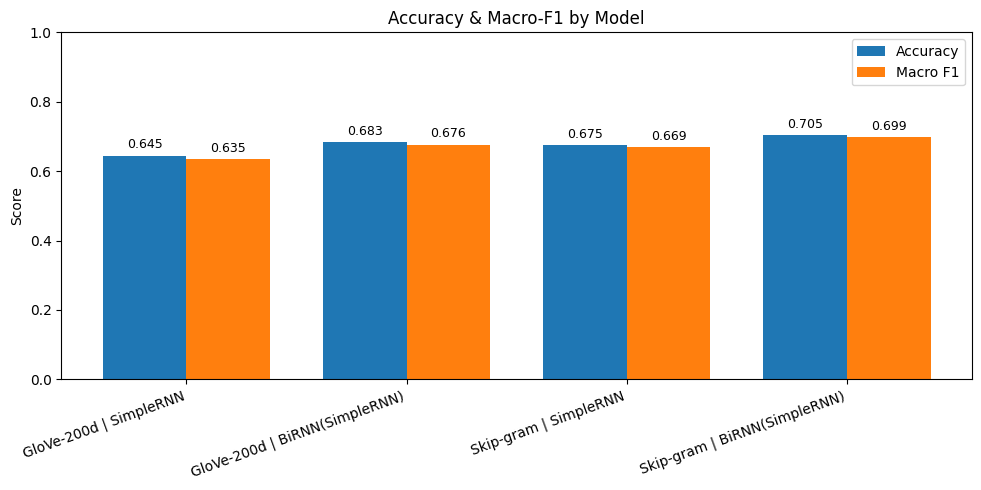

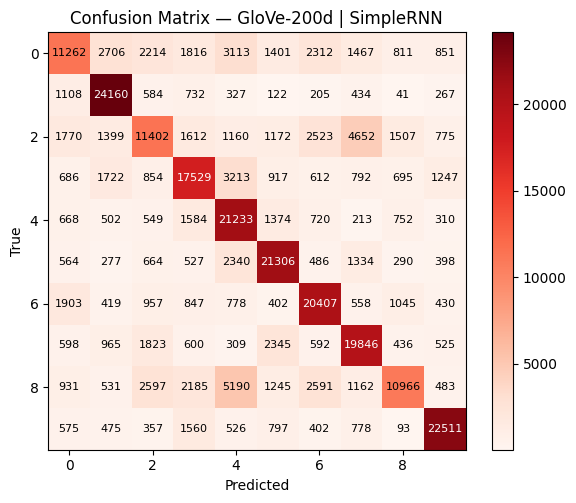

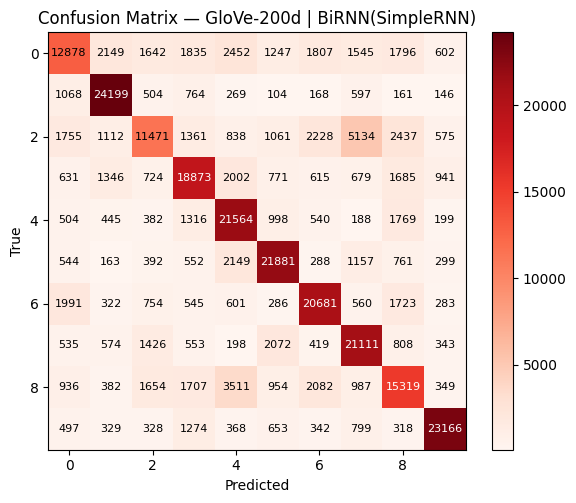

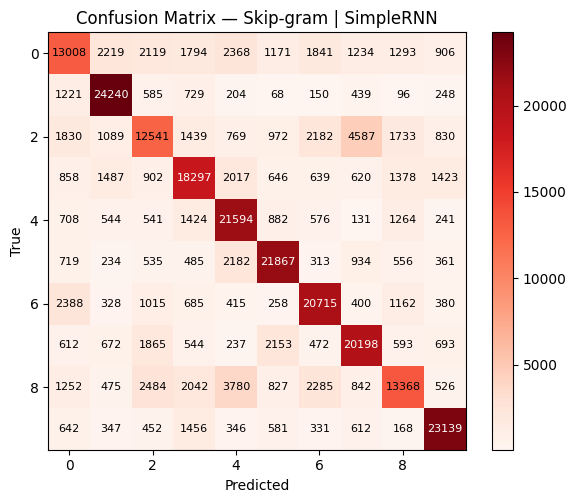

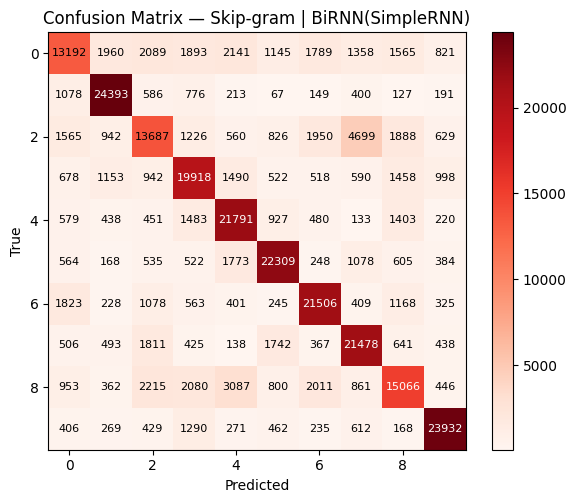

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

# ---- which results to plot (left name = pretty label shown on plots, right key = results[...] key) ---
pairs = [
    ("GloVe-200d | SimpleRNN",        "glove_rnn"),
    ("GloVe-200d | BiRNN(SimpleRNN)", "glove_birnn"),
    ("Skip-gram | SimpleRNN",         "skipgram_rnn"),
    ("Skip-gram | BiRNN(SimpleRNN)",  "skipgram_birnn"),
]

# ---- gather metrics and confusion matrices ----
labels   = []
accs     = []
f1s      = []
cms      = {}

for pretty, key in pairs:
    labels.append(pretty)
    pred = results[key]["pred"]
    acc  = results[key].get("acc", accuracy_score(y_test, pred))
    f1   = results[key].get("f1_macro", f1_score(y_test, pred, average="macro"))
    accs.append(acc)
    f1s.append(f1)
    cms[pretty] = confusion_matrix(y_test, pred)

# ---- single grouped barplot: blue = accuracy, orange = macro-F1 ----
x = np.arange(len(labels))
w = 0.38  # bar width

plt.figure(figsize=(10,5))
b1 = plt.bar(x - w/2, accs, width=w, label="Accuracy", color="tab:blue")
b2 = plt.bar(x + w/2, f1s,  width=w, label="Macro F1", color="tab:orange")

plt.xticks(x, labels, rotation=20, ha="right")
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Accuracy & Macro-F1 by Model")
plt.legend()

# annotate values on bars
def _annotate(bars):
    for bar in bars:
        h = bar.get_height()
        plt.annotate(f"{h:.3f}",
                     xy=(bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha="center", va="bottom", fontsize=9)
_annotate(b1); _annotate(b2)

plt.tight_layout()
plt.show()

# ---- confusion matrices with a clearer colormap ----
# choose a perceptually-uniform map; 'magma' has good contrast
for name, cm in cms.items():
    plt.figure(figsize=(6,5))
    im = plt.imshow(cm, interpolation="nearest", cmap="Reds")
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    cbar = plt.colorbar(im)

    # annotate counts with readable text color
    vmax = cm.max() if cm.size else 1
    thresh = vmax * 0.6
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = cm[i, j]
            txt_color = "white" if v >= thresh else "black"
            plt.text(j, i, f"{v}", ha="center", va="center", color=txt_color, fontsize=8)

    plt.tight_layout()
    plt.show()